####
Peform the spectral signature characterization

In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import os
from matplotlib import cm, colors as mcolors



import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from scipy.optimize import curve_fit
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD


In [2]:
# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum at ONE time step.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=17)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=17)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()


    return results_outliers



def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask

In [3]:

def analyse_rfi(freq, power, peak_freqs,
                 threshold=0.05,
                 plot=True):
    """
    Characterise each detected RFI outlier in a single-time-step spectrum.
 
    For every frequency listed in `peak_freqs`, this computes two
    complementary bandwidth estimates:
 
    1. Threshold-crossing bandwidth: the extent (in frequency) over which
       the detrended power stays above a fixed absolute `threshold`,
       measured by walking outward from the peak until the power drops
       below that level. This is useful for counting how many channels
       are contaminated above your flagging threshold.
 
    2. FWHM (Full Width at Half Maximum): the width of the peak at half
       its prominence above the local baseline, computed via
       `scipy.signal.peak_widths` with `rel_height=0.5`. This is the
       standard spectral-linewidth definition and is directly comparable
       to known service channel bandwidths (e.g. ~200 kHz for GSM).
 
    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum), in MHz.
    power : 1D array
        Detrended/baseline-corrected power spectrum at ONE time step
        (linear power, not dB).
    peak_freqs : list or 1D array
        Frequencies (MHz) of detected outlier peaks.
    threshold : float
        Absolute power level used to define the rise/fall crossing for
        the threshold-based bandwidth (metric 1 above).
    plot : bool
        If True, produce one diagnostic plot per outlier.
    save_dir : str or None
        If given, save each plot as PNG/PDF into this directory.
        If None, plots are shown but not saved.
 
    Returns
    -------
    results : list of dict
        One dictionary per outlier, containing both bandwidth estimates,
        peak frequency/power, and the number of contaminated channels.
    """
 
    freq = np.asarray(freq)
    power = np.asarray(power)
    freq_resolution = freq[1] - freq[0]
 
    # -----------------------------------------------------------------
    # Convert peak frequencies -> nearest array indices (needed for
    # peak_widths, which operates on integer index positions)
    # -----------------------------------------------------------------
    peak_indices = np.array(
        [np.argmin(np.abs(freq - pf)) for pf in peak_freqs]
    )
 
    # -----------------------------------------------------------------
    # FWHM for ALL peaks at once (vectorised call, rel_height=0.5 =>
    # half-maximum relative to each peak's own prominence)
    # -----------------------------------------------------------------
    widths_idx, width_heights, left_ips, right_ips = peak_widths(
        power, peak_indices, rel_height=0.5
    )
    fwhm_freq = widths_idx * freq_resolution
 
    # -----------------------------------------------------------------
    # Sanity check: a zero-width / zero-prominence result means the
    # supplied peak_freqs did not line up with a true local maximum in
    # `power` (e.g. peak_freqs came from a different array/step than
    # the one passed in here). Warn loudly rather than silently
    # returning a meaningless FWHM of 0.
    # -----------------------------------------------------------------
    # for i, w in enumerate(widths_idx):
    #     if w == 0:
    #         warnings.warn(
    #             f"Peak at {peak_freqs[i]:.4f} MHz has zero FWHM/prominence. "
    #             "This usually means peak_freqs was not derived from "
    #             "find_peaks(power, ...) on this same array. Pass the "
    #             "find_peaks indices/frequencies directly to avoid this.",
    #             RuntimeWarning,
    #         )
 
    idx_axis = np.arange(len(freq))
    fwhm_left_freq = np.interp(left_ips, idx_axis, freq)
    fwhm_right_freq = np.interp(right_ips, idx_axis, freq)
 
    results = []
 
    for i, peak_f in enumerate(peak_freqs):
 
        peak_index = peak_indices[i]
        peak_power = power[peak_index]
 
        # ---------------------------------------------------------
        # Threshold-crossing bandwidth (manual walk, absolute level)
        # ---------------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1
        start_freq = freq[left_index]
 
        right_index = peak_index
        while right_index < len(power) - 1 and power[right_index] > threshold:
            right_index += 1
        end_freq = freq[right_index]
 
        bandwidth = end_freq - start_freq
        n_channels = right_index - left_index + 1
 
        # ---------------------------------------------------------
        # Collect results
        # ---------------------------------------------------------
        result = {
            "peak_freq_mhz": freq[peak_index],
            "peak_power": peak_power,
            "threshold_start_freq_mhz": start_freq,
            "threshold_end_freq_mhz": end_freq,
            "threshold_bandwidth_mhz": bandwidth,
            "n_channels_above_threshold": n_channels,
            "fwhm_mhz": fwhm_freq[i],
            "fwhm_khz": fwhm_freq[i] * 1e3,
            "fwhm_left_freq_mhz": fwhm_left_freq[i],
            "fwhm_right_freq_mhz": fwhm_right_freq[i],
            "fwhm_half_max_power": width_heights[i],
        }
        results.append(result)
 
        print(f"\nOutlier {i + 1}:")
        print(f"  Peak Frequency        : {result['peak_freq_mhz']:.4f} MHz")
        print(f"  Peak Power            : {result['peak_power']:.4f}")
        print(f"  Threshold Start Freq  : {start_freq:.4f} MHz")
        print(f"  Threshold End Freq    : {end_freq:.4f} MHz")
        print(f"  Threshold Bandwidth   : {bandwidth * 1e3:.2f} kHz")
        print(f"  Channels > threshold  : {n_channels}")
        print(f"  FWHM                  : {result['fwhm_khz']:.2f} kHz")
 
        # ---------------------------------------------------------
        # Plot (one figure per outlier, zoomed around the peak)
        # ---------------------------------------------------------
        if plot:
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq) - 1)
 
            fig, ax = plt.subplots(figsize=(9, 5))
 
            ax.plot(freq[lo:hi], power[lo:hi], color="steelblue", lw=1,
                    label="Spectrum")
            ax.plot(freq[peak_index], power[peak_index], "rx", ms=8, mew=2,
                    label="Detected peak")
 
            # FWHM span (half-max, from peak_widths)
            ax.hlines(
                width_heights[i], fwhm_left_freq[i], fwhm_right_freq[i],
                color="darkorange", lw=2, label="FWHM (half-max)"
            )
            ax.vlines(
                [fwhm_left_freq[i], fwhm_right_freq[i]],
                ymin=power[lo:hi].min(), ymax=width_heights[i],
                color="gray", linestyle="--", lw=0.8
            )
 
            # Threshold-crossing span (absolute level)
            ax.axhline(threshold, color="green", linestyle=":", lw=1,
                       label=f"Threshold = {threshold}")
            ax.axvline(start_freq, color="green", linestyle=":", lw=0.8)
            ax.axvline(end_freq, color="green", linestyle=":", lw=0.8)
 
            ax.annotate(
                f"FWHM = {result['fwhm_khz']:.1f} kHz",
                xy=(freq[peak_index], power[peak_index]),
                xytext=(freq[peak_index], power[peak_index] * 1.15),
                ha="center", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="black", lw=0.8)
            )
 
            ax.set_xlabel("Frequency (MHz)")
            ax.set_ylabel("Power (linear)")
            ax.set_title(f"Outlier {i + 1} at {freq[peak_index]:.4f} MHz")
            ax.legend(loc="upper right", fontsize=8)
            ax.grid(alpha=0.3)
            fig.tight_layout()
 
            # if save_dir is not None:
            #     fig.savefig(
            #         f"{save_dir}/outlier_{i + 1}_at_{freq[peak_index]:.4f}MHz.png",
            #         dpi=300, bbox_inches="tight"
            #     )
            #     fig.savefig(
            #         f"{save_dir}/outlier_{i + 1}_at_{freq[peak_index]:.4f}MHz.pdf",
            #         dpi=300, bbox_inches="tight"
            #     )
            # plt.close(fig)
 
    return results

In [4]:


# ---------------------------------------------------------------
# Gaussian model with a constant offset (baseline)
# ---------------------------------------------------------------
def gaussian(x, amplitude, centre, sigma, offset):
    return offset + amplitude * np.exp(-0.5 * ((x - centre) / sigma) ** 2)


def chi_squared(y_data, y_fit, y_err, n_params):
    """
    Chi-squared and reduced chi-squared goodness-of-fit.

    Parameters
    ----------
    y_data : array
        Observed values.
    y_fit : array
        Model-predicted values at the same x positions.
    y_err : array or float
        Per-point measurement uncertainty (standard deviation).
        Can be a scalar (constant noise) or an array (per-bin noise).
    n_params : int
        Number of free parameters in the fitted model (4 for our
        Gaussian: amplitude, centre, sigma, offset).

    Returns
    -------
    chi2 : float
        Raw chi-squared statistic.
    chi2_reduced : float
        Chi-squared divided by degrees of freedom (N - n_params).
        chi2_reduced ~ 1 indicates a good fit given the stated
        uncertainties; >> 1 indicates a poor fit (or underestimated
        uncertainties); << 1 indicates overestimated uncertainties.
    """
    residuals = y_data - y_fit
    chi2 = np.sum((residuals / y_err) ** 2)
    dof = len(y_data) - n_params
    chi2_reduced = chi2 / dof
    return chi2, chi2_reduced



In [5]:
# Define RFI bands (GHz) for MeerKAT S-band (1.75–3.5 GHz)
rfi_bands = {

"Cellular GSM Uplink": (1710, 1785),

"Cellular GSM Downlink": (1805, 1880),

"DECT Phones": (1880, 1900),

"UMTS Uplink": (1920, 1980),

"UMTS Downlink": (2110, 2170),

"Mobile Satellite": (2000, 2200),

"Space Research / EESS": (2200, 2290),

"IMT 2300 (4G/5G)": (2300, 2400),

"Wi-Fi / Bluetooth (ISM)": (2400, 2483),

"LTE / 5G (2600 band)": (2500, 2690),

"Air Traffic Radar": (2700, 2900),

"Weather Radar": (2700, 3000),

"Microwave Backhaul": (3000, 3300),

"5G NR (n78)": (3300, 3600)

}

colors = [
"#E41A1C","#377EB8","#4DAF4A","#984EA3","#FF7F00",
"#FFFF33","#A65628","#F781BF","#999999","#66C2A5",
"#FC8D62","#8DA0CB","#E78AC3","#A6D854"
]


transition_bands = {
    "Gap: GSM DL to GSM UL": (1.785, 1.805),
    "Gap: DECT to UMTS UL": (1.90, 1.92),
    "Gap: UMTS UL to MSS": (1.98, 2.00),
    "Gap: EESS to IMT-2300": (2.29, 2.30),
    "Gap: ISM to LTE 2600": (2.483, 2.50),
    "Gap: LTE 2600 to Radar": (2.69, 2.70),

    #"Overlap: MSS and UMTS DL": (2.11, 2.17),
    #"Overlap: Radar and Weather": (2.70, 2.90)
}

# combinne both bands
all_bands = dict(sorted(
    {**rfi_bands, **transition_bands}.items(),
    key=lambda item: item[1][0]  # sort by lower frequency
))

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [6]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False  # Set to True to save the plots, False to just display them


In [7]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e6 # MHz
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [8]:
datasets.keys()

dict_keys(['scan/000/P1_ND0', 'scan/000/P1_ND1', 'scan/001/P0_ND0', 'scan/001/P0_ND1', 'scan/001/P1_ND0', 'scan/001/P1_ND1'])

In [9]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, integration_time: 634,
                       ra: 634, dec: 634, elevation: 634, azimuth: 634)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 511kB 1.793e+03 ... 3.498e+03
  * integration_time  (integration_time) float64 5kB 0.1158 0.1129 ... 0.1159
  * ra                (ra) float64 5kB 82.06 82.06 82.07 ... 85.21 85.22 85.22
  * dec               (dec) float64 5kB 22.68 22.68 22.68 ... 21.3 21.3 21.29
  * elevation         (elevation) float64 5kB 30.51 30.5 30.51 ... 30.51 30.51
  * azimuth           (azimuth) float64 5kB 29.42 29.42 29.42 ... 32.78 32.79
Data variables:
    spectrum          (time, frequency) float32 162MB 1.883e+11 ... 4.159e+09

In [10]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_mhz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values



# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


/tmp/ipykernel_243540/2987960714.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=16, loc='center left', bbox_to_anchor=(1, 0.5))


Peaks detected ['1819.6278', '2002.7828', '2184.1488', '2199.9302', '2362.8979', '2492.0063'] MHz


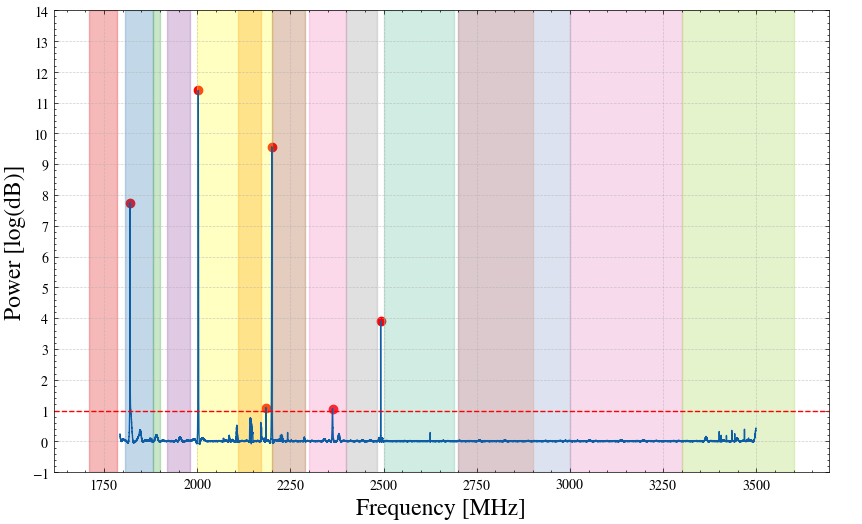

In [11]:
# perfom the time average and peak ideintification

spectrum_corrected = base_correction(frequency_mhz, mean_spectrum_db)

# Peak detection

sigma_value_high = 3
    # Detect peaks
threshold = MAD(spectrum_corrected) + sigma_value_high * np.std(spectrum_corrected)
peaks, properties = find_peaks(spectrum_corrected,
                                height=threshold,
                                prominence=0.5,
                                distance=80
                                )

# Plot
plt.figure(figsize=(10, 6))
plt.plot(frequency_mhz, spectrum_corrected)#, label=f'Detrended signal')
plt.scatter(frequency_mhz[peaks], spectrum_corrected[peaks], color='red')#, label='Peaks')
plt.axhline(y=threshold, color='red', linestyle='--')#, label=f'MAD + {sigma_value_high}$σ$')

plt.xlabel('Frequency [MHz]',fontsize=17)
plt.ylabel('Power [log(dB)]',fontsize=17)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=16, loc='center left', bbox_to_anchor=(1, 0.5))


yticks=np.arange(-1, 15)
plt.yticks(yticks)

# --- Overlay RFI bands ---
for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
    plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)


# --- Print detected peak frequencies ---
formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]

print(f"Peaks detected {formatted_freqs} MHz")

plt.show()

In [12]:
res = frequency_mhz[1] - frequency_mhz[0]
res

np.float64(0.026702880859375)

In [13]:
# define the FWHM

widths_idx, width_heights, left_ips, right_ips = peak_widths(
    spectrum_corrected, peaks, rel_height=0.5)

# frequency resolution
freq_resolution = frequency_mhz[1] - frequency_mhz[0]
fwhm_freq = widths_idx * freq_resolution



for i, pk in enumerate(peaks):
    print(f"Peak at {frequency_mhz[pk]:.4f} MHz | FWHM = {fwhm_freq[i]:.4f} MHz "
          f"| half-max level = {width_heights[i]:.4e}")

Peak at 1819.6278 MHz | FWHM = 0.5625 MHz | half-max level = 3.8441e+00
Peak at 2002.7828 MHz | FWHM = 0.8770 MHz | half-max level = 5.6618e+00
Peak at 2184.1488 MHz | FWHM = 0.0422 MHz | half-max level = 5.1776e-01
Peak at 2199.9302 MHz | FWHM = 0.8736 MHz | half-max level = 4.7471e+00
Peak at 2362.8979 MHz | FWHM = 1.9312 MHz | half-max level = 5.2236e-01
Peak at 2492.0063 MHz | FWHM = 0.0381 MHz | half-max level = 1.9409e+00


Peak frequencies (MHz): [1819.62776184 2002.78282166 2184.14878845 2199.93019104 2362.89787292
 2492.00630188]
FWHM (MHz): [0.5624746  0.87695437 0.04220332 0.87362877 1.93119679 0.0381038 ]
FWHM (kHz): [ 562.47459933  876.95436794   42.20331635  873.62877034 1931.19678568
   38.1037997 ]


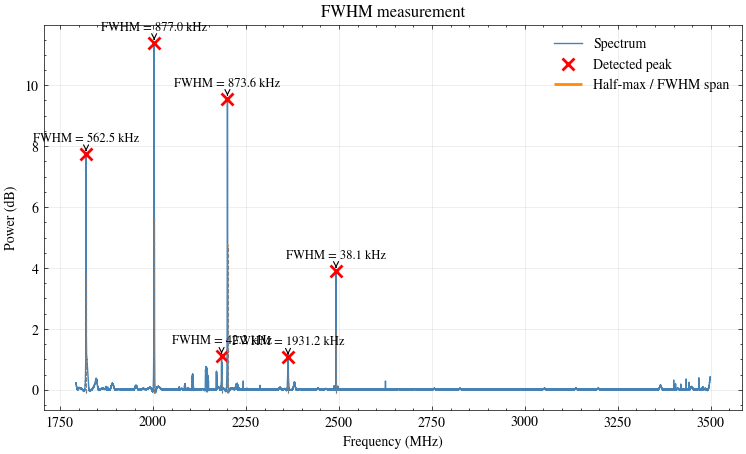

In [14]:

 
# Convert fractional index crossings to frequency values
idx_axis = np.arange(len(frequency_mhz))
left_freq = np.interp(left_ips, idx_axis, frequency_mhz)
right_freq = np.interp(right_ips, idx_axis, frequency_mhz)
 
# ---------------------------------------------------------------
# 4. Plot
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
 
ax.plot(frequency_mhz, spectrum_corrected, color="steelblue", lw=1, label="Spectrum")
ax.plot(frequency_mhz[peaks], spectrum_corrected[peaks], "rx", ms=8, mew=2, label="Detected peak")
 
# Half-max horizontal lines (crossing level) and FWHM span
for i in range(len(peaks)):
    ax.hlines(
        width_heights[i], left_freq[i], right_freq[i],
        color="darkorange", lw=2,
        label="Half-max / FWHM span" if i == 0 else None
    )
    # Vertical guides marking the crossing points
    ax.vlines(
        [left_freq[i], right_freq[i]],
        ymin=spectrum_corrected.min(), ymax=width_heights[i],
        color="gray", linestyle="--", lw=0.8
    )
    # Annotate FWHM value
    ax.annotate(
        f"FWHM = {fwhm_freq[i]*1e3:.1f} kHz",
        xy=(frequency_mhz[peaks[i]], spectrum_corrected[peaks[i]]),
        xytext=(frequency_mhz[peaks[i]], spectrum_corrected[peaks[i]] + 0.4),
        ha="center", fontsize=9,
        arrowprops=dict(arrowstyle="->", color="black", lw=0.8)
    )
 
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Power (dB)")
ax.set_title("FWHM measurement")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
 
# fig.tight_layout()
print("Peak frequencies (MHz):", frequency_mhz[peaks])
print("FWHM (MHz):", fwhm_freq)
print("FWHM (kHz):", fwhm_freq * 1e3)

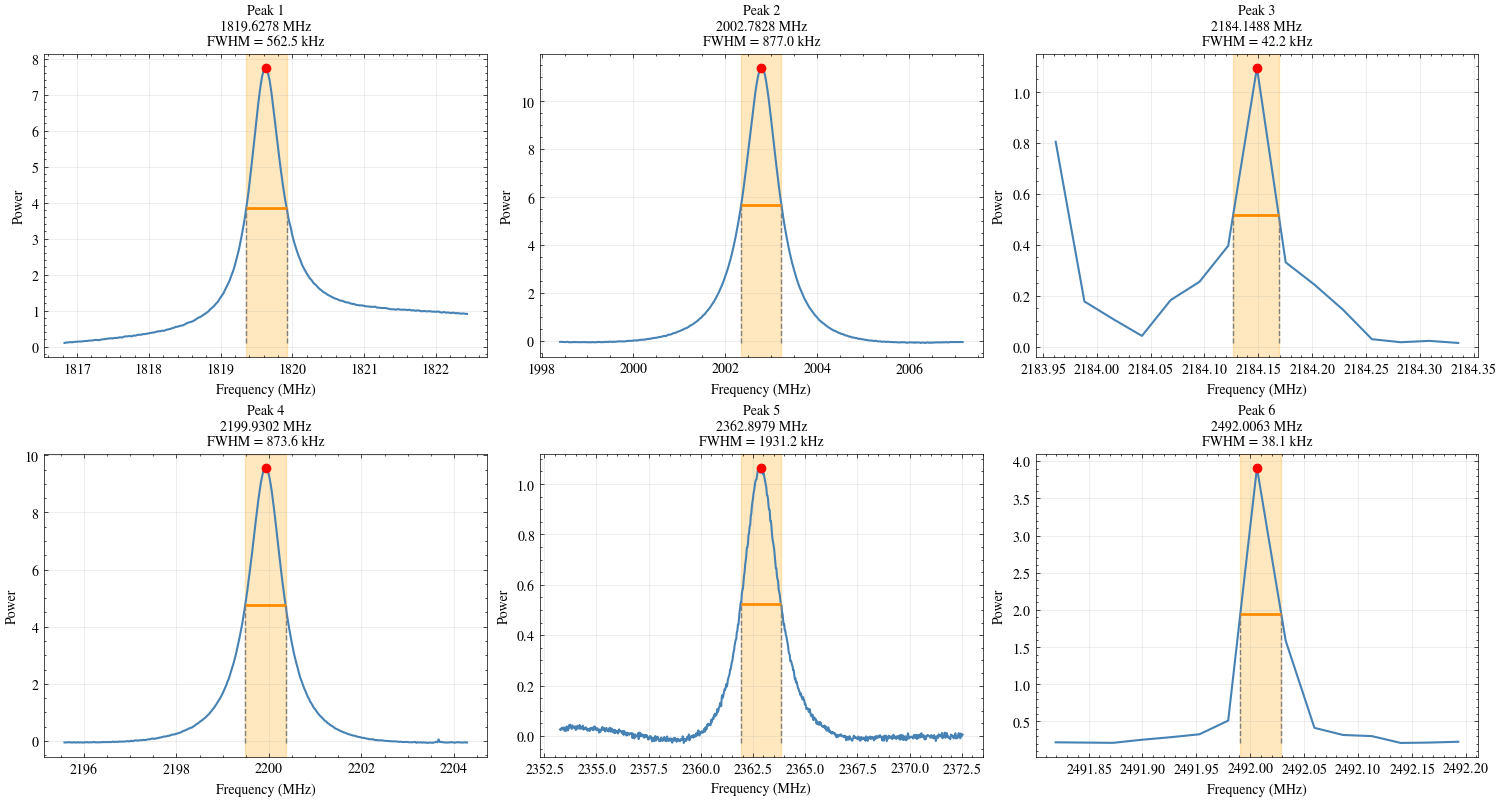

In [ ]:

import math

# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak

n_peaks = len(peaks)

ncols = 3
nrows = math.ceil(n_peaks / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5*ncols, 4*nrows),
    constrained_layout=True
)

axes = np.atleast_1d(axes).flatten()

for i, peak in enumerate(peaks):

    ax = axes[i]

    centre = frequency_mhz[peak]

    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq[i]
    x_max = centre + window * fwhm_freq[i]

    mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)

    # Spectrum
    ax.plot(
        frequency_mhz[mask],
        spectrum_corrected[mask],
        color="steelblue",
        lw=1.5
    )

    # Peak marker
    ax.plot(
        centre,
        spectrum_corrected[peak],
        'ro',
        ms=6,
        label='Peak'
    )

    # FWHM line
    ax.hlines(
        width_heights[i],
        left_freq[i],
        right_freq[i],
        color='darkorange',
        lw=2,
        label='FWHM'
    )

    # Crossing points
    ax.vlines(
        [left_freq[i], right_freq[i]],
        ymin=spectrum_corrected[mask].min(),
        ymax=width_heights[i],
        color='gray',
        linestyle='--'
    )

    # Shade the FWHM
    ax.axvspan(
        left_freq[i],
        right_freq[i],
        color='orange',
        alpha=0.25
    )

    ax.set_title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq[i]*1000:.1f} kHz",
        fontsize=10
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power")
    ax.grid(alpha=0.3)

# Remove empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.show()

In [16]:
# add a gaussian function to each plot
def gaussian(x, A, mu, sigma, C):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2)) + C

In [17]:
mean_spectrum_db.shape

(63877,)

In [18]:
for i, peak in enumerate(peaks):

    print('Power:', mean_spectrum_db[peak])

Power: 254.7773360328248
Power: 259.4343332069593
Power: 250.0415987616272
Power: 259.26751040118415
Power: 251.08545749915123
Power: 253.88873622488674


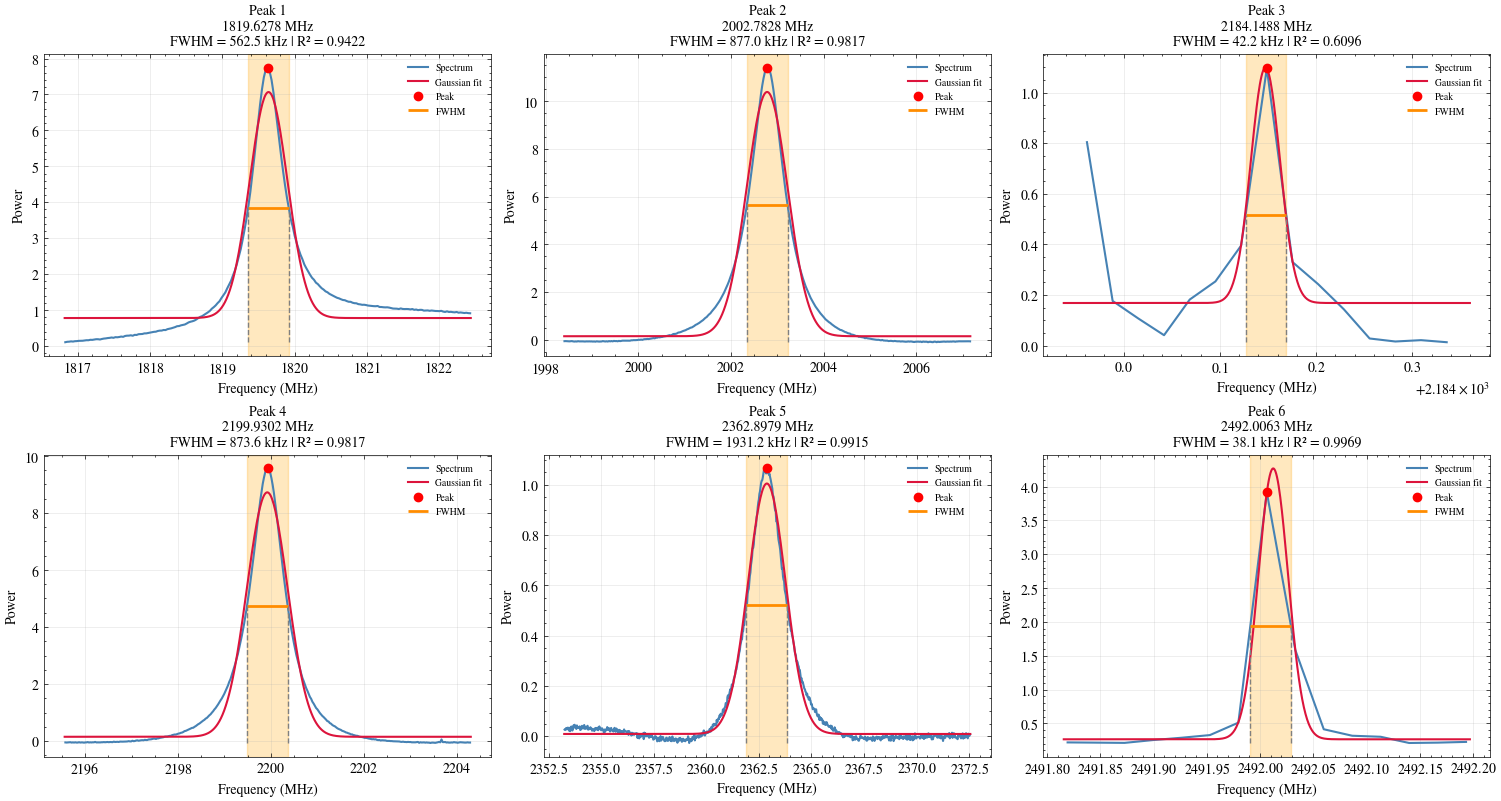

In [19]:

# # ---------------------------------------------------------------
# # Gaussian model with a constant offset (baseline)
# # ---------------------------------------------------------------
# def gaussian(x, amplitude, centre, sigma, offset):
#     return offset + amplitude * np.exp(-0.5 * ((x - centre) / sigma) ** 2)
 
 
def r_squared(y_data, y_fit):
    """Coefficient of determination R^2."""
    ss_res = np.sum((y_data - y_fit) ** 2)
    ss_tot = np.sum((y_data - np.mean(y_data)) ** 2)
    return 1 - ss_res / ss_tot
 

 
# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak
 
n_peaks = len(peaks)
 
ncols = 3
nrows = math.ceil(n_peaks / ncols)
 
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 4 * nrows),
    constrained_layout=True
)
 
axes = np.atleast_1d(axes).flatten()
 
gaussian_fit_results = []  # collect fit params + R^2 per peak
 
for i, peak in enumerate(peaks):
 
    ax = axes[i]
 
    centre = frequency_mhz[peak]
 
    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq[i]
    x_max = centre + window * fwhm_freq[i]
 
    mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)
 
    x_data = frequency_mhz[mask]
    y_data = spectrum_corrected[mask]
 
    # -------------------------------------------------------
    # Gaussian fit
    # -------------------------------------------------------
    # FWHM = 2*sqrt(2*ln2)*sigma  =>  sigma = FWHM / 2.3548
    sigma_guess = fwhm_freq[i] / 2.3548
    amp_guess = spectrum_corrected[peak] - np.median(y_data)
    offset_guess = np.median(y_data)
 
    p0 = [amp_guess, centre, sigma_guess, offset_guess]
 
    try:
        popt, pcov = curve_fit(gaussian, x_data, y_data, p0=p0, maxfev=10000)
        y_fit_at_data = gaussian(x_data, *popt)
        r2 = r_squared(y_data, y_fit_at_data)
 
        # Smooth curve for plotting
        x_smooth = np.linspace(x_min, x_max, 500)
        y_smooth = gaussian(x_smooth, *popt)
 
        fit_success = True
    except RuntimeError:
        popt = [np.nan] * 4
        r2 = np.nan
        x_smooth, y_smooth = None, None
        fit_success = False
 
    gaussian_fit_results.append({
        "peak_freq_mhz": centre,
        "amplitude": popt[0],
        "fitted_centre_mhz": popt[1],
        "sigma_mhz": popt[2],
        "offset": popt[3],
        "r_squared": r2,
        "fit_success": fit_success,
    })

    
    # -------------------------------------------------------
    # Spectrum
    # -------------------------------------------------------
    ax.plot(
        x_data,
        y_data,
        color="steelblue",
        lw=1.5,
        label="Spectrum"
    )
 
    # Gaussian fit overlay
    if fit_success:
        ax.plot(
            x_smooth,
            y_smooth,
            color="crimson",
            lw=1.5,
            linestyle="-",
            label="Gaussian fit"
        )
 
    # Peak marker
    ax.plot(
        centre,
        spectrum_corrected[peak],
        'ro',
        ms=6,
        label='Peak'
    )
 
    # FWHM line
    ax.hlines(
        width_heights[i],
        left_freq[i],
        right_freq[i],
        color='darkorange',
        lw=2,
        label='FWHM'
    )
 
    # Crossing points
    ax.vlines(
        [left_freq[i], right_freq[i]],
        ymin=y_data.min(),
        ymax=width_heights[i],
        color='gray',
        linestyle='--'
    )
 
    # Shade the FWHM
    ax.axvspan(
        left_freq[i],
        right_freq[i],
        color='orange',
        alpha=0.25
    )
 
    r2_str = f"{r2:.4f}" if fit_success else "fit failed"
    ax.set_title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq[i]*1000:.1f} kHz | R\u00b2 = {r2_str}",
        fontsize=10
    )
 
    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")



# # Remove empty axes
# fig.tight_layout()

# if to_save:
#     fig.savefig(
#         "gaussian_peak_fits.png",
#         dpi=300,
#         bbox_inches="tight",
#         facecolor="white"
#     )
 
plt.show()
 

In [20]:
gaussian_fit_results

[{'peak_freq_mhz': np.float64(1819.6277618408203),
  'amplitude': np.float64(6.291887363585186),
  'fitted_centre_mhz': np.float64(1819.6392819824946),
  'sigma_mhz': np.float64(0.262101951130836),
  'offset': np.float64(0.776330047548977),
  'r_squared': np.float64(0.9421759042838207),
  'fit_success': True},
 {'peak_freq_mhz': np.float64(2002.7828216552734),
  'amplitude': np.float64(10.22529967731122),
  'fitted_centre_mhz': np.float64(2002.7797305474273),
  'sigma_mhz': np.float64(0.4424939895033084),
  'offset': np.float64(0.1549940084480972),
  'r_squared': np.float64(0.9816623529059645),
  'fit_success': True},
 {'peak_freq_mhz': np.float64(2184.1487884521484),
  'amplitude': np.float64(0.9291955006066729),
  'fitted_centre_mhz': np.float64(2184.1473612176587),
  'sigma_mhz': np.float64(0.015119733805824919),
  'offset': np.float64(0.1689674909616817),
  'r_squared': np.float64(0.6095818902044932),
  'fit_success': True},
 {'peak_freq_mhz': np.float64(2199.930191040039),
  'ampl

In [21]:

# for i, peak in enumerate(peaks):
#     fit_result = gaussian_fit_results[i]

 
#     centre = frequency_mhz[peak]
 
#     # Zoom window proportional to the measured FWHM
#     x_min = centre - window * fwhm_freq[i]
#     x_max = centre + window * fwhm_freq[i]
 
#     mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)
 
#     x_data = frequency_mhz[mask]
#     y_data = spectrum_corrected[mask]

#     # determine the OBW
#     total_power = np.sum(y_data)
#     cumulative_power = np.cumsum(y_data)
#     lower_bound_idx = np.searchsorted(cumulative_power, 0.05 * total_power)
#     upper_bound_idx = np.searchsorted(cumulative_power, 0.95 * total_power)
#     obw_lower_freq = x_data[lower_bound_idx]
#     obw_upper_freq = x_data[upper_bound_idx]    

#     occupied_bandwidth = obw_upper_freq - obw_lower_freq

#     # ratio obw to fwhm
#     obw_to_fwhm_ratio = occupied_bandwidth / fwhm_freq[i]
    
#     print(f"Peak {i+1}:")
#     print(f"  Detected Frequency: {fit_result['peak_freq_mhz']:.4f} MHz")
#     print(f"  Gaussian Fitted Frequency: {fit_result['fitted_centre_mhz']:.4f} MHz")
#     print(f"  Fitted Amplitude: {fit_result['amplitude']:.4f}")
#     print(f"  Signal Amplitude: {spectrum_corrected[peak]:.4f}")
#     print(f"  Occupied Bandwidth: {occupied_bandwidth:.1f} MHz")
#     print(f"  FWHM              : {fwhm_freq[i]:.1f} MHz")
#     print(f"  OBW/FWHM Ratio    : {obw_to_fwhm_ratio:.4f}")

#     high_peak_details.append({
        
#         "detected_frequency": fit_result['peak_freq_mhz'],
#         "fitted_frequency": fit_result['fitted_centre_mhz'],
#         "fitted_amplitude": fit_result['amplitude'],
#         "signal_amplitude": spectrum_corrected[peak],
#         "occupied_bandwidth": occupied_bandwidth,
#         "fwhm": fwhm_freq[i],
#         "obw_to_fwhm_ratio": obw_to_fwhm_ratio
#     })


/tmp/ipykernel_243540/3259453922.py:178: UserWarning: Glyph 7525 (\N{LATIN SUBSCRIPT SMALL LETTER V}) missing from font(s) STIXGeneral.
  fig.tight_layout()
/tmp/ipykernel_243540/3259453922.py:178: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 7525 (\N{LATIN SUBSCRIPT SMALL LETTER V}) missing from font(s) STIXGeneral.
  fig.canvas.print_figure(bytes_io, **kw)


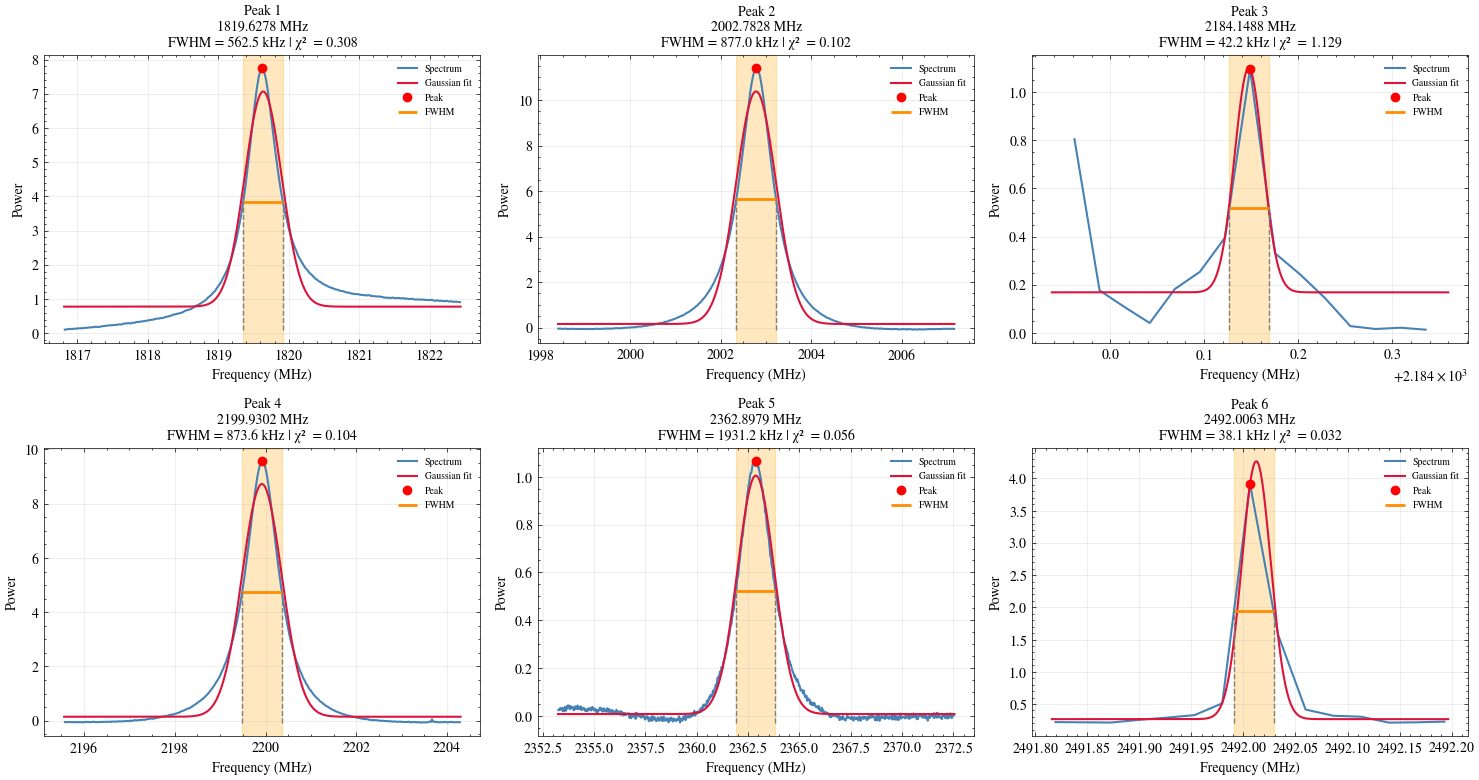

In [ ]:

high_peak_details = []


# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak

n_peaks = len(peaks)

ncols = 3
nrows = math.ceil(n_peaks / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 4 * nrows),
    constrained_layout=True
)

axes = np.atleast_1d(axes).flatten()

gaussian_fit_results = []  # collect fit params + chi-squared per peak

# -----------------------------------------------------------------
# OPTIONAL: supply your own per-channel noise estimate here instead of
# deriving it from the off-peak wings of each fit window. If you have
# a radiometer-noise estimate (e.g. std of an RFI-free reference
# region, or from your binned statistics module), set:
#
#   external_noise_std = <float or 1D array matching frequency_mhz>
#
# and it will be used in place of the off-peak-wing estimate below.
# Leave as None to fall back on the off-peak-wing estimate.
# -----------------------------------------------------------------
external_noise_std = None

for i, peak in enumerate(peaks):

    ax = axes[i]

    centre = frequency_mhz[peak]

    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq[i]
    x_max = centre + window * fwhm_freq[i]

    mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)

    x_data = frequency_mhz[mask]
    y_data = spectrum_corrected[mask]

    # -------------------------------------------------------
    # Estimate per-point noise (sigma) for chi-squared
    # -------------------------------------------------------
    if external_noise_std is not None:
        if np.isscalar(external_noise_std):
            noise_std = external_noise_std
        else:
            noise_std = np.median(np.asarray(external_noise_std)[mask])
    else:
        off_peak_mask = (x_data < left_freq[i]) | (x_data > right_freq[i])
        if np.sum(off_peak_mask) > 5:
            noise_std = np.std(y_data[off_peak_mask])
        else:
            noise_std = np.std(y_data)

    if noise_std == 0:
        noise_std = 1e-6  # guard against a zero-noise edge case

    # -------------------------------------------------------
    # Gaussian fit
    # -------------------------------------------------------
    sigma_guess = fwhm_freq[i] / 2.3548
    amp_guess = spectrum_corrected[peak] #- np.median(y_data)
    offset_guess = np.median(y_data)

    p0 = [amp_guess, centre, sigma_guess, offset_guess]

    try:
        popt, pcov = curve_fit(
            gaussian, x_data, y_data, p0=p0,
            sigma=noise_std, absolute_sigma=True, maxfev=10000
            )
        y_fit_at_data = gaussian(x_data, *popt)
        chi2, chi2_reduced = chi_squared(
            y_data, y_fit_at_data, noise_std, n_params=4
        )

        x_smooth = np.linspace(x_min, x_max, 500)
        y_smooth = gaussian(x_smooth, *popt)

        fit_success = True
    except RuntimeError:
        popt = [np.nan] * 4
        chi2, chi2_reduced = np.nan, np.nan
        x_smooth, y_smooth = None, None
        fit_success = False

    gaussian_fit_results.append({
        "peak_freq_mhz": centre,
        "amplitude": popt[0],
        "fitted_centre_mhz": popt[1],
        "sigma_mhz": popt[2],
        "offset": popt[3],
        "noise_std": noise_std,
        "chi_squared": chi2,
        "reduced_chi_squared": chi2_reduced,
        "fit_success": fit_success,
    })


    # determine the OBW
    total_power = np.sum(y_data)
    cumulative_power = np.cumsum(y_data)
    lower_bound_idx = np.searchsorted(cumulative_power, 0.05 * total_power)
    upper_bound_idx = np.searchsorted(cumulative_power, 0.95 * total_power)
    obw_lower_freq = x_data[lower_bound_idx]
    obw_upper_freq = x_data[upper_bound_idx] 

    #occupaied bandwidth
    occupied_bandwidth = obw_upper_freq - obw_lower_freq

    # ratio obw to fwhm
    obw_to_fwhm_ratio = occupied_bandwidth / fwhm_freq[i]
      

    # create a data frame to store the results
    
    high_peak_details.append({
    
    "detected_frequency_[MHz]": centre,
    "fitted_frequency_[MHz]": popt[1],
    "fitted_amplitude_[dB]": popt[0],
    "detrended_signal_[dB]": spectrum_corrected[peak],
    "signal_amplitude_[dB]": mean_spectrum_db[peak],
    "occupied_bandwidth_[MHz]": occupied_bandwidth,
    "fwhm_[MHz]": fwhm_freq[i],
    "obw_to_fwhm_ratio": obw_to_fwhm_ratio
    })


    # -------------------------------------------------------
    # Spectrum
    # -------------------------------------------------------
    ax.plot(x_data, y_data, color="steelblue", lw=1.5, label="Spectrum")

    if fit_success:
        ax.plot(x_smooth, y_smooth, color="crimson", lw=1.5,
                 linestyle="-", label="Gaussian fit")

    ax.plot(centre, spectrum_corrected[peak], 'ro', ms=6, label='Peak')

    ax.hlines(width_heights[i], left_freq[i], right_freq[i],
              color='darkorange', lw=2, label='FWHM')

    ax.vlines([left_freq[i], right_freq[i]],
              ymin=y_data.min(), ymax=width_heights[i],
              color='gray', linestyle='--')

    ax.axvspan(left_freq[i], right_freq[i], color='orange', alpha=0.25)

    chi2_str = f"{chi2_reduced:.3f}" if fit_success else "fit failed"
    ax.set_title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq[i]*1000:.1f} kHz | \u03c7\u00b2\u1d65 = {chi2_str}",
        fontsize=10
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")


# Remove empty axes
fig.tight_layout()

if to_save:
        # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_high_peak_gaussian_fits.png'),
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_high_peak_gaussian_fits.pdf'),
        bbox_inches="tight",
        facecolor="white"
    )


plt.show()

# gaussian_fit_results now holds, per peak:
#   fitted amplitude, centre, sigma, offset, noise_std,
#   chi_squared, and reduced_chi_squared

In [23]:
# create full path
full_path = os.path.join(dirname, scan_name)
# create the directory if they don't exist
os.makedirs(full_path, exist_ok=True)

if to_save:

    # convert the list into a DataFrame for better visualization
    high_peak_df = pd.DataFrame(high_peak_details)
    high_peak_df.to_csv(
        os.path.join(full_path, f"{dirname}_high_peak_details.csv"),
        index=False
    )


In [24]:
high_peak_df= pd.read_csv(os.path.join(full_path, f"{dirname}_high_peak_details.csv"))
high_peak_df

,detected_frequency_[MHz],fitted_frequency_[MHz],fitted_amplitude_[dB],detrended_signal_[dB],signal_amplitude_[dB],occupied_bandwidth_[MHz],fwhm_[MHz],obw_to_fwhm_ratio
0,1819.627762,1819.639282,6.291893,7.746628,254.777336,3.631592,0.562475,6.456455
1,2002.782822,2002.779731,10.225300,11.396878,259.434333,2.029419,0.876954,2.314167
2,2184.148788,2184.147361,0.929195,1.095014,250.041599,0.267029,0.042203,6.327200
3,2199.930191,2199.920505,8.575429,9.563067,259.267510,2.082825,0.873629,2.384107
4,2362.897873,2362.878643,0.996114,1.064483,251.085457,3.631592,1.931197,1.880488
5,2492.006302,2492.012307,4.003498,3.913530,253.888736,0.267029,0.038104,7.007931



Outlier 1:
  Peak Frequency : 1819.6278 GHz
  Peak Power     : 7.7466 dB
  Start Frequency: 1816.2899 GHz
  End Frequency  : 1827.0779 GHz
  Bandwidth      : 10.7880 GHz
  Corrupted Ch.  : 404 channels

Outlier 2:
  Peak Frequency : 2002.7828 GHz
  Peak Power     : 11.3969 dB
  Start Frequency: 2000.2460 GHz
  End Frequency  : 2005.0259 GHz
  Bandwidth      : 4.7798 GHz
  Corrupted Ch.  : 179 channels

Outlier 3:
  Peak Frequency : 2184.1488 GHz
  Peak Power     : 1.0950 dB
  Start Frequency: 2184.0420 GHz
  End Frequency  : 2184.2556 GHz
  Bandwidth      : 0.2136 GHz
  Corrupted Ch.  : 8 channels

Outlier 4:
  Peak Frequency : 2199.9302 GHz
  Peak Power     : 9.5631 dB
  Start Frequency: 2197.3400 GHz
  End Frequency  : 2202.2800 GHz
  Bandwidth      : 4.9400 GHz
  Corrupted Ch.  : 185 channels

Outlier 5:
  Peak Frequency : 2362.8979 GHz
  Peak Power     : 1.0645 dB
  Start Frequency: 2360.4679 GHz
  End Frequency  : 2365.5415 GHz
  Bandwidth      : 5.0735 GHz
  Corrupted Ch.  : 190

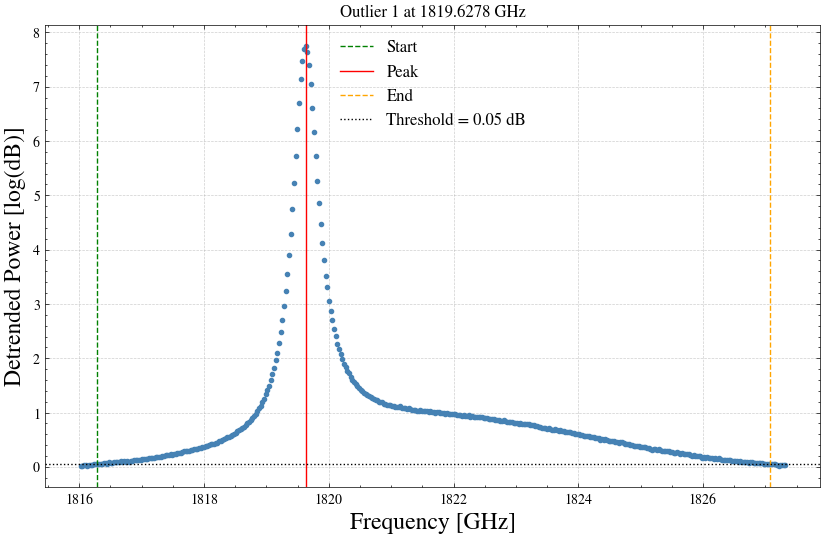

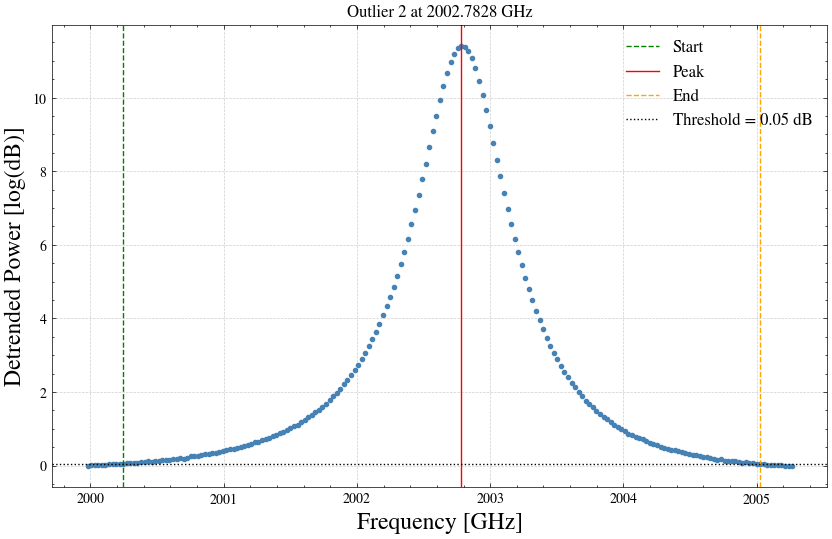

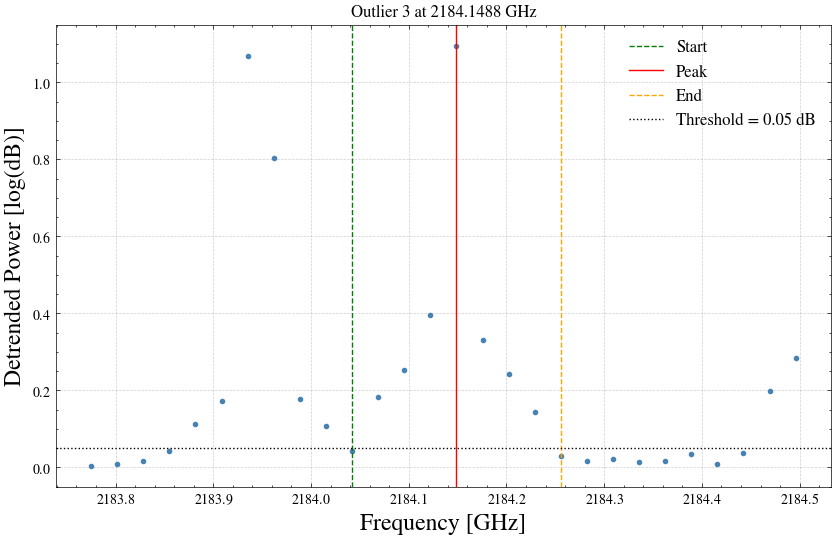

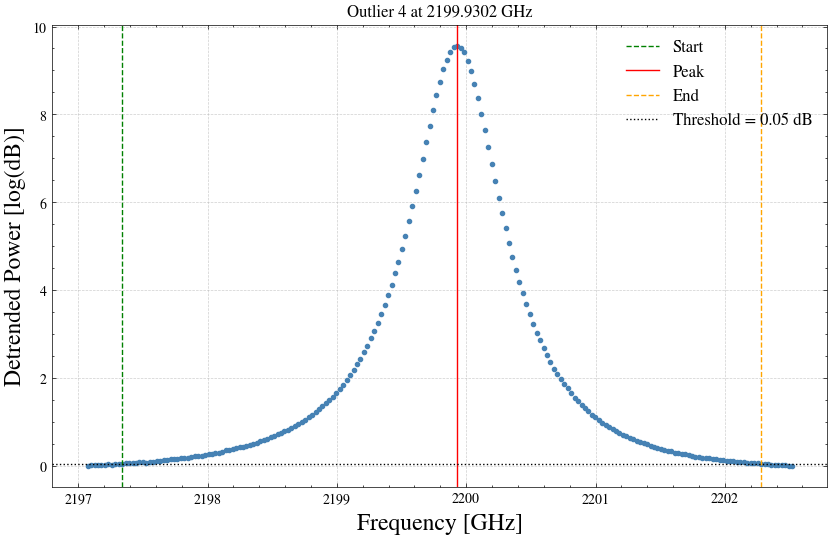

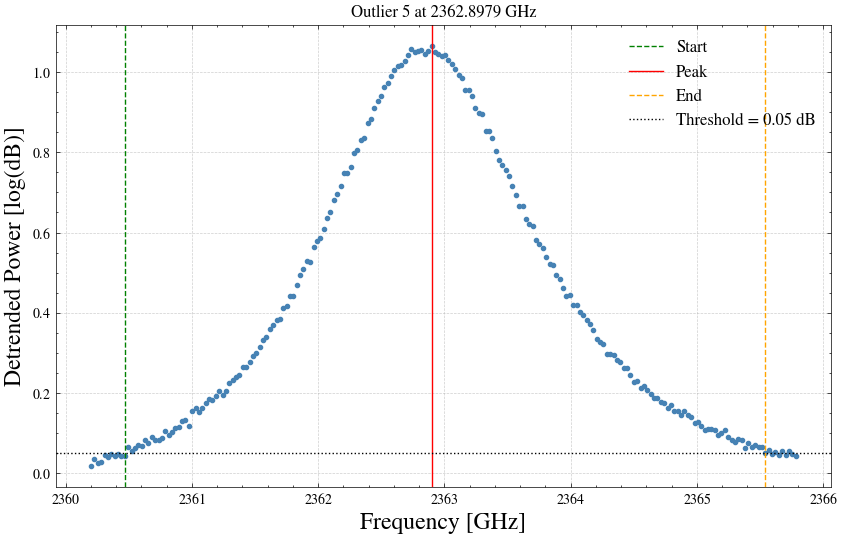

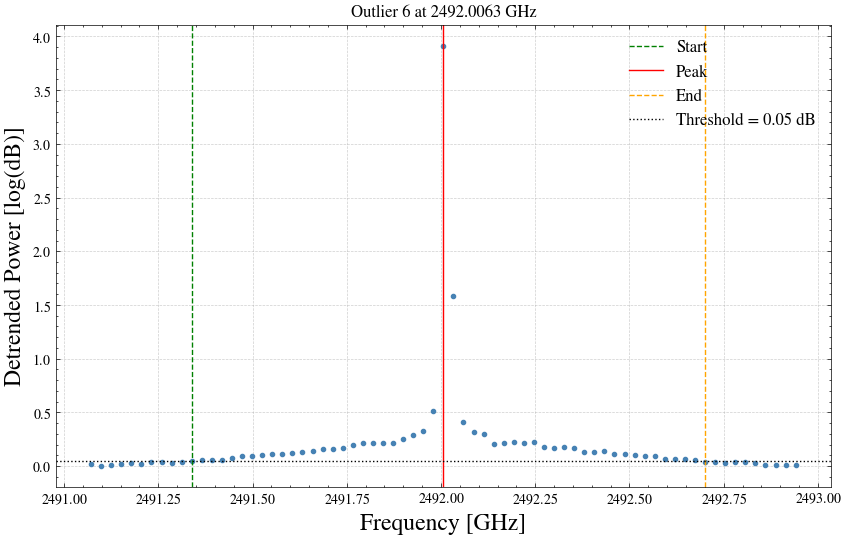

In [25]:
results_outliers = quantify_all_outliers(frequency_mhz, spectrum_corrected, frequency_mhz[peaks], plot=True)


Peaks detected at [14:58:44]: ['1846.7846', '2106.3900', '2142.0918', '2145.8836', '2170.3434', '2183.9352', '2242.4679', '2624.9866', '3400.3048', '3433.9771', '3467.9966'] MHz


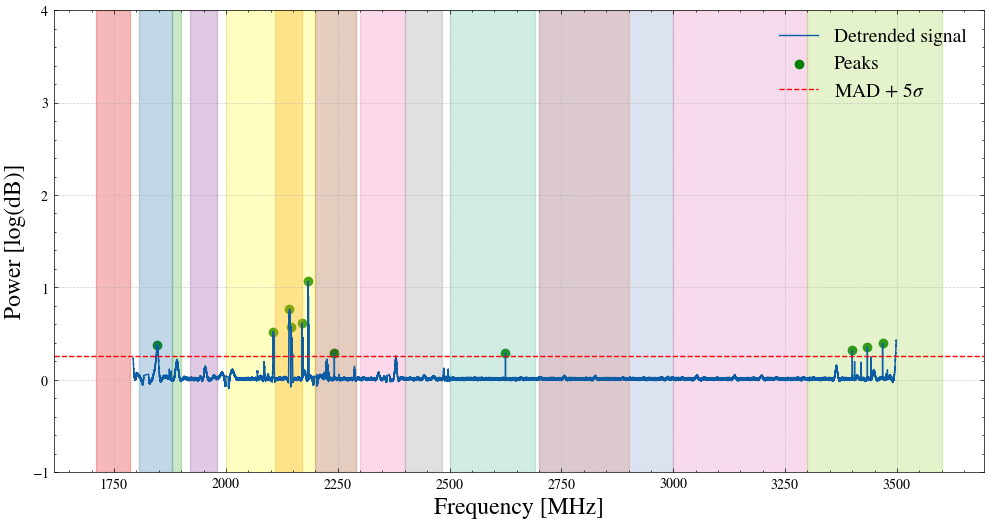

In [26]:

mask_high = build_rfi_mask(frequency_mhz, results_outliers)

# make a copy of the spectrum
mask_signal = spectrum_corrected.copy()

# replace the flagged channels with NaN
mask_signal = mask_signal[~mask_high]
mask_frequency = frequency_mhz[~mask_high]

 
sigma_value_low = 5 
threshold = MAD(mask_signal) + sigma_value_low * np.std(mask_signal)

peaks_low, properties = find_peaks(
    mask_signal,
    height=threshold,
    prominence=0.3,
    distance=110
)

# 5) Plot
plt.figure(figsize=(12, 6))
plt.plot(mask_frequency, mask_signal, label='Detrended signal')
plt.scatter(mask_frequency[peaks_low], mask_signal[peaks_low], 
            color='green', label='Peaks')

plt.axhline(y=threshold, color='red', linestyle='--',
            label=f'MAD + {sigma_value_low}$σ$')

plt.xlabel('Frequency [MHz]', fontsize=17)
plt.ylabel('Power [log(dB)]', fontsize=17)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=14)

#define the yticks size the same for all the plots
yticks=np.arange(-1, 5, 1)
plt.yticks(yticks)

# --- Overlay RFI bands ---
for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
    plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)


formatted_freqs = [f"{f:.4f}" for f in mask_frequency[peaks_low]]
print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} MHz")

# plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/low_level_peak_plot.png', dpi=300, bbox_inches='tight')
# plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/low_level_peak_plot.pdf', dpi=300, bbox_inches='tight')


plt.show()


In [27]:
threshold

np.float64(0.2597961732953038)


Outlier 1:
  Peak Frequency : 1835.9699 GHz
  Peak Power     : 0.0265 dB
  Start Frequency: 1835.9699 GHz
  End Frequency  : 1835.9699 GHz
  Bandwidth      : 0.0000 GHz
  Corrupted Ch.  : 0 channels

Outlier 2:
  Peak Frequency : 2090.7688 GHz
  Peak Power     : 0.0090 dB
  Start Frequency: 2090.7688 GHz
  End Frequency  : 2090.7688 GHz
  Bandwidth      : 0.0000 GHz
  Corrupted Ch.  : 0 channels

Outlier 3:
  Peak Frequency : 2126.4706 GHz
  Peak Power     : 0.0104 dB
  Start Frequency: 2126.4706 GHz
  End Frequency  : 2126.4706 GHz
  Bandwidth      : 0.0000 GHz
  Corrupted Ch.  : 0 channels

Outlier 4:
  Peak Frequency : 2130.2624 GHz
  Peak Power     : 0.0140 dB
  Start Frequency: 2130.2624 GHz
  End Frequency  : 2130.2624 GHz
  Bandwidth      : 0.0000 GHz
  Corrupted Ch.  : 0 channels

Outlier 5:
  Peak Frequency : 2154.7222 GHz
  Peak Power     : 0.0084 dB
  Start Frequency: 2154.7222 GHz
  End Frequency  : 2154.7222 GHz
  Bandwidth      : 0.0000 GHz
  Corrupted Ch.  : 0 channels


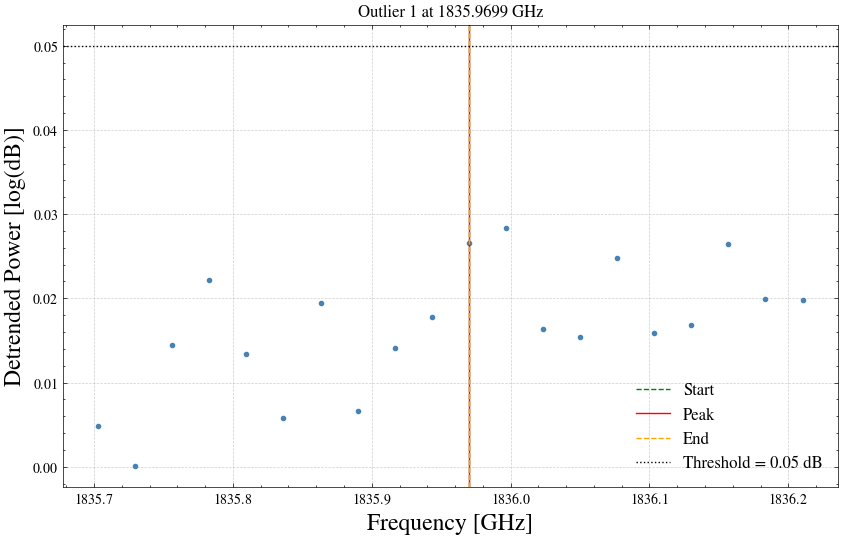

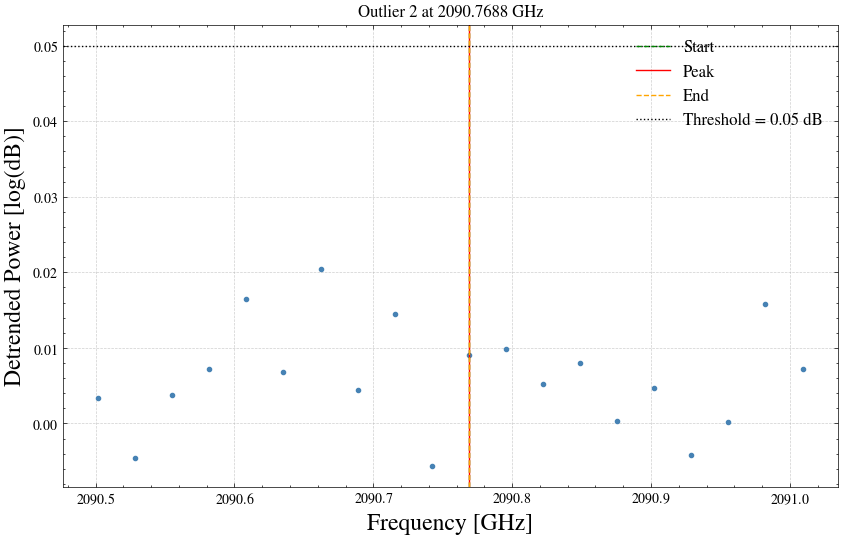

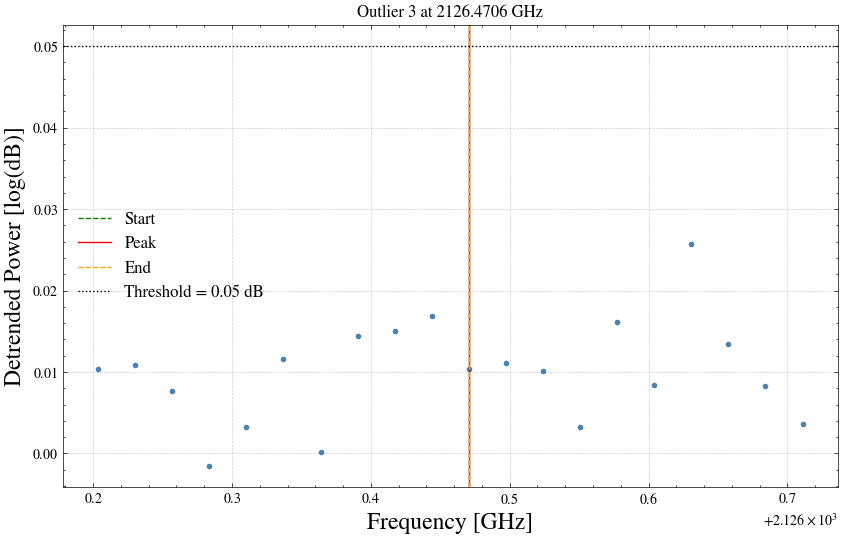

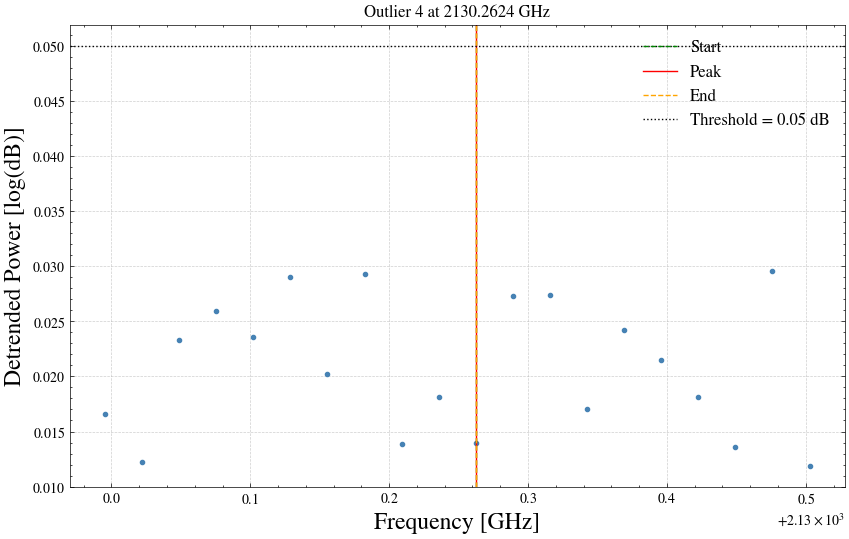

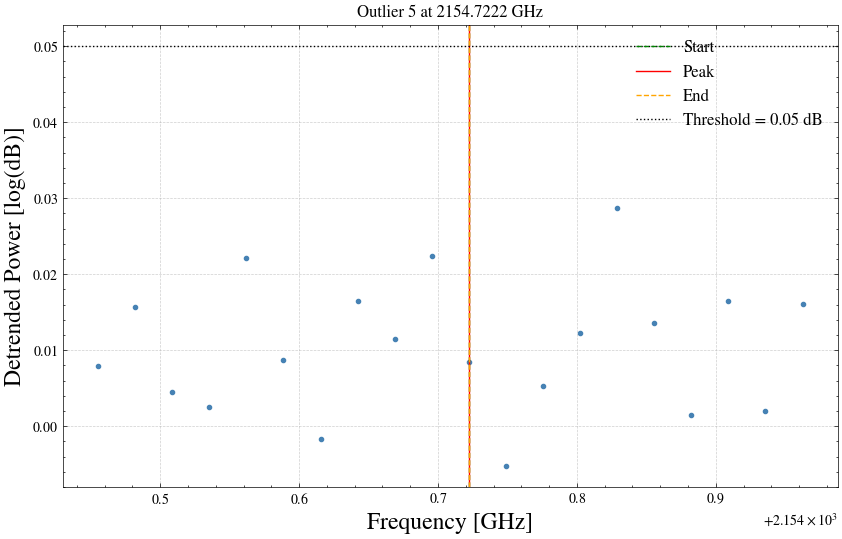

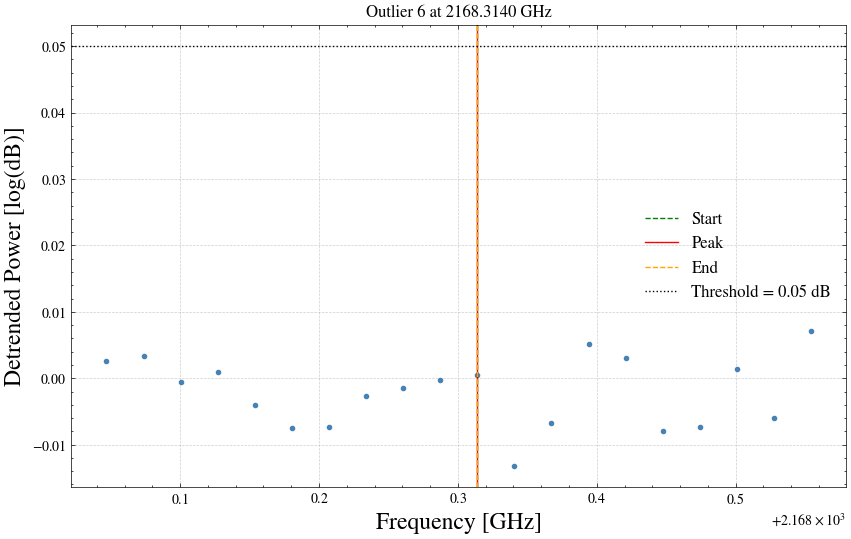

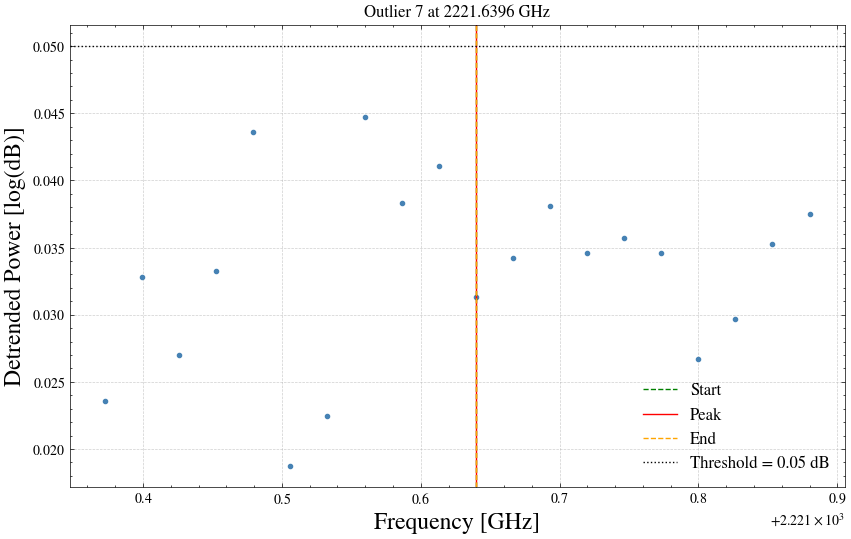

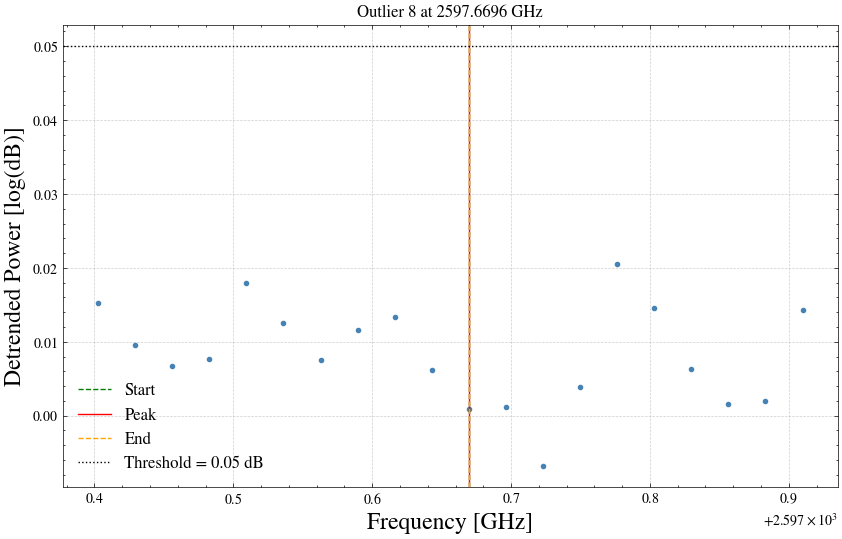

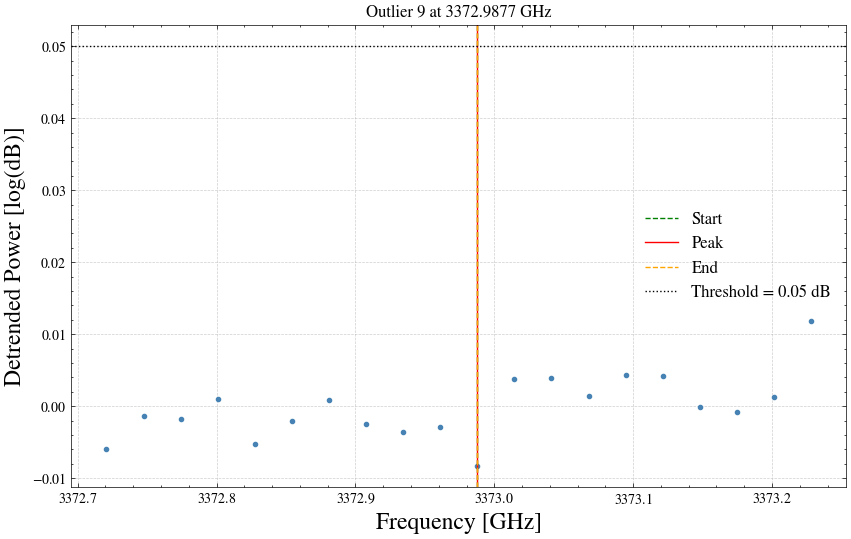

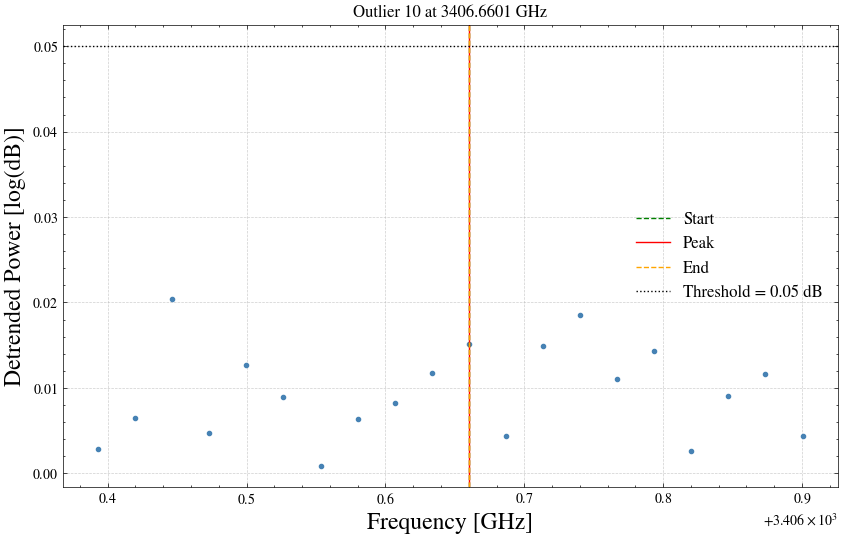

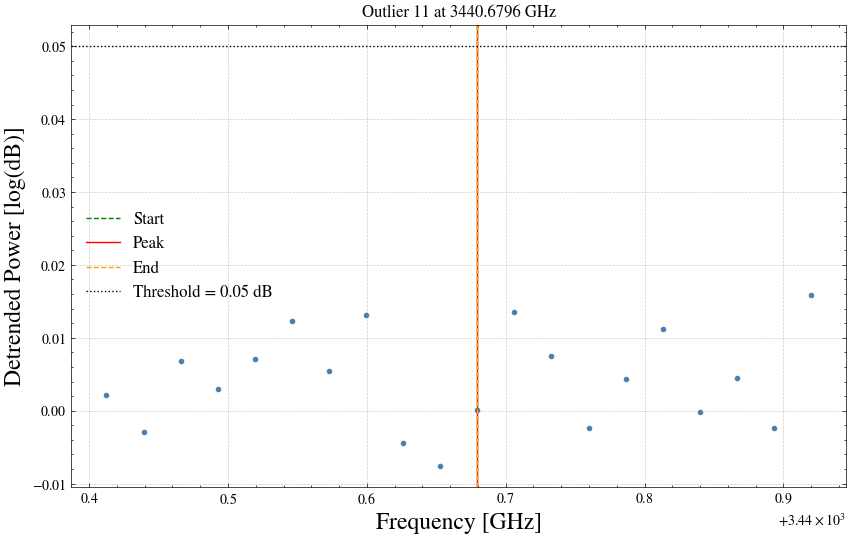

In [28]:
results_outliers_low = quantify_all_outliers(mask_frequency, mask_signal, frequency_mhz[peaks_low], plot=True)


In [29]:
# analyse low level peaks
# define the FWHM

widths_idx_low, width_heights_low, left_ips_low, right_ips_low = peak_widths(
    mask_signal,peaks_low , rel_height=0.5)

# frequency resolution
fwhm_freq_low = widths_idx_low * freq_resolution



for i, pk in enumerate(peaks_low):
    print(f"Peak at {frequency_mhz[pk]:.4f} MHz | FWHM = {fwhm_freq_low[i]:.4f} MHz "
          f"| half-max level = {width_heights_low[i]:.4e}")

Peak at 1835.9699 MHz | FWHM = 7.5582 MHz | half-max level = 1.6126e-01
Peak at 2090.7688 MHz | FWHM = 1.4913 MHz | half-max level = 2.4503e-01
Peak at 2126.4706 MHz | FWHM = 3.7841 MHz | half-max level = 3.4414e-01
Peak at 2130.2624 MHz | FWHM = 2.8145 MHz | half-max level = 2.7222e-01
Peak at 2154.7222 MHz | FWHM = 0.0388 MHz | half-max level = 3.0026e-01
Peak at 2168.3140 MHz | FWHM = 0.0566 MHz | half-max level = 4.9940e-01
Peak at 2221.6396 MHz | FWHM = 0.0504 MHz | half-max level = 1.3103e-01
Peak at 2597.6696 MHz | FWHM = 0.0296 MHz | half-max level = 1.3466e-01
Peak at 3372.9877 MHz | FWHM = 0.0351 MHz | half-max level = 1.5045e-01
Peak at 3406.6601 MHz | FWHM = 0.0502 MHz | half-max level = 1.7084e-01
Peak at 3440.6796 MHz | FWHM = 0.2416 MHz | half-max level = 1.8151e-01


Peak frequencies (MHz): [1830.44242859 2018.40400696 2204.97703552 2220.75843811 2388.82637024
 2519.323349  ]
FWHM (MHz): [7.55815532 1.4912753  3.78406572 2.81454566 0.03879943 0.0566427
 0.0504494  0.02956286 0.03508786 0.05018097 0.24156959]
FWHM (kHz): [7558.15531672 1491.27529574 3784.06571807 2814.54565676   38.7994344
   56.64270496   50.44939668   29.56285872   35.08785927   50.18096696
  241.56958897]


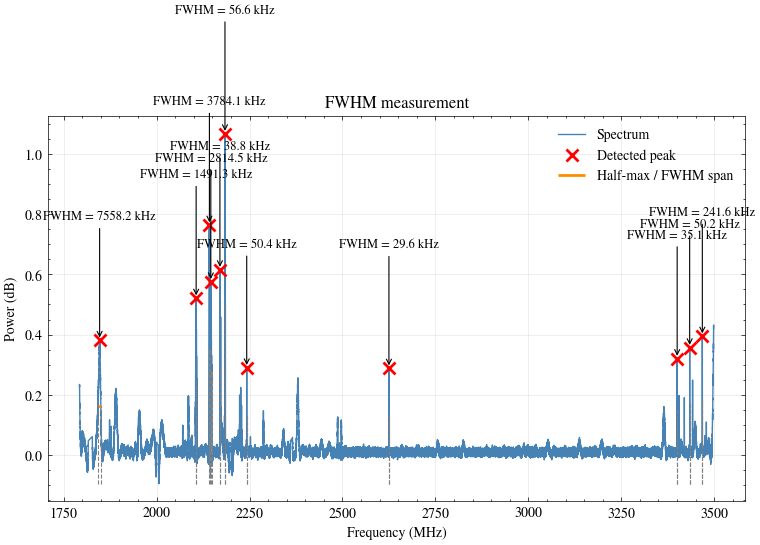

In [30]:

 
# Convert fractional index crossings to frequency values
idx_axis_low = np.arange(len(mask_frequency))
left_freq_low = np.interp(left_ips_low, idx_axis_low, mask_frequency)
right_freq_low = np.interp(right_ips_low, idx_axis_low, mask_frequency)
 
# ---------------------------------------------------------------
# 4. Plot
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
 
ax.plot(mask_frequency, mask_signal, color="steelblue", lw=1, label="Spectrum")
ax.plot(mask_frequency[peaks_low], mask_signal[peaks_low], "rx", ms=8, mew=2, label="Detected peak")
 
# Half-max horizontal lines (crossing level) and FWHM span
for i in range(len(peaks_low)):
    ax.hlines(
        width_heights_low[i], left_freq_low[i], right_freq_low[i],
        color="darkorange", lw=2,
        label="Half-max / FWHM span" if i == 0 else None
    )
    # Vertical guides marking the crossing points
    ax.vlines(
        [left_freq_low[i], right_freq_low[i]],
        ymin=mask_signal.min(), ymax=width_heights_low[i],
        color="gray", linestyle="--", lw=0.8
    )
    # Annotate FWHM value
    ax.annotate(
        f"FWHM = {fwhm_freq_low[i]*1e3:.1f} kHz",
        xy=(mask_frequency[peaks_low[i]], mask_signal[peaks_low[i]]),
        xytext=(mask_frequency[peaks_low[i]], mask_signal[peaks_low[i]] + 0.4),
        ha="center", fontsize=9,
        arrowprops=dict(arrowstyle="->", color="black", lw=0.8)
    )
 
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Power (dB)")
ax.set_title("FWHM measurement")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
 
# fig.tight_layout()
print("Peak frequencies (MHz):", mask_frequency[peaks])
print("FWHM (MHz):", fwhm_freq_low)
print("FWHM (kHz):", fwhm_freq_low * 1e3)

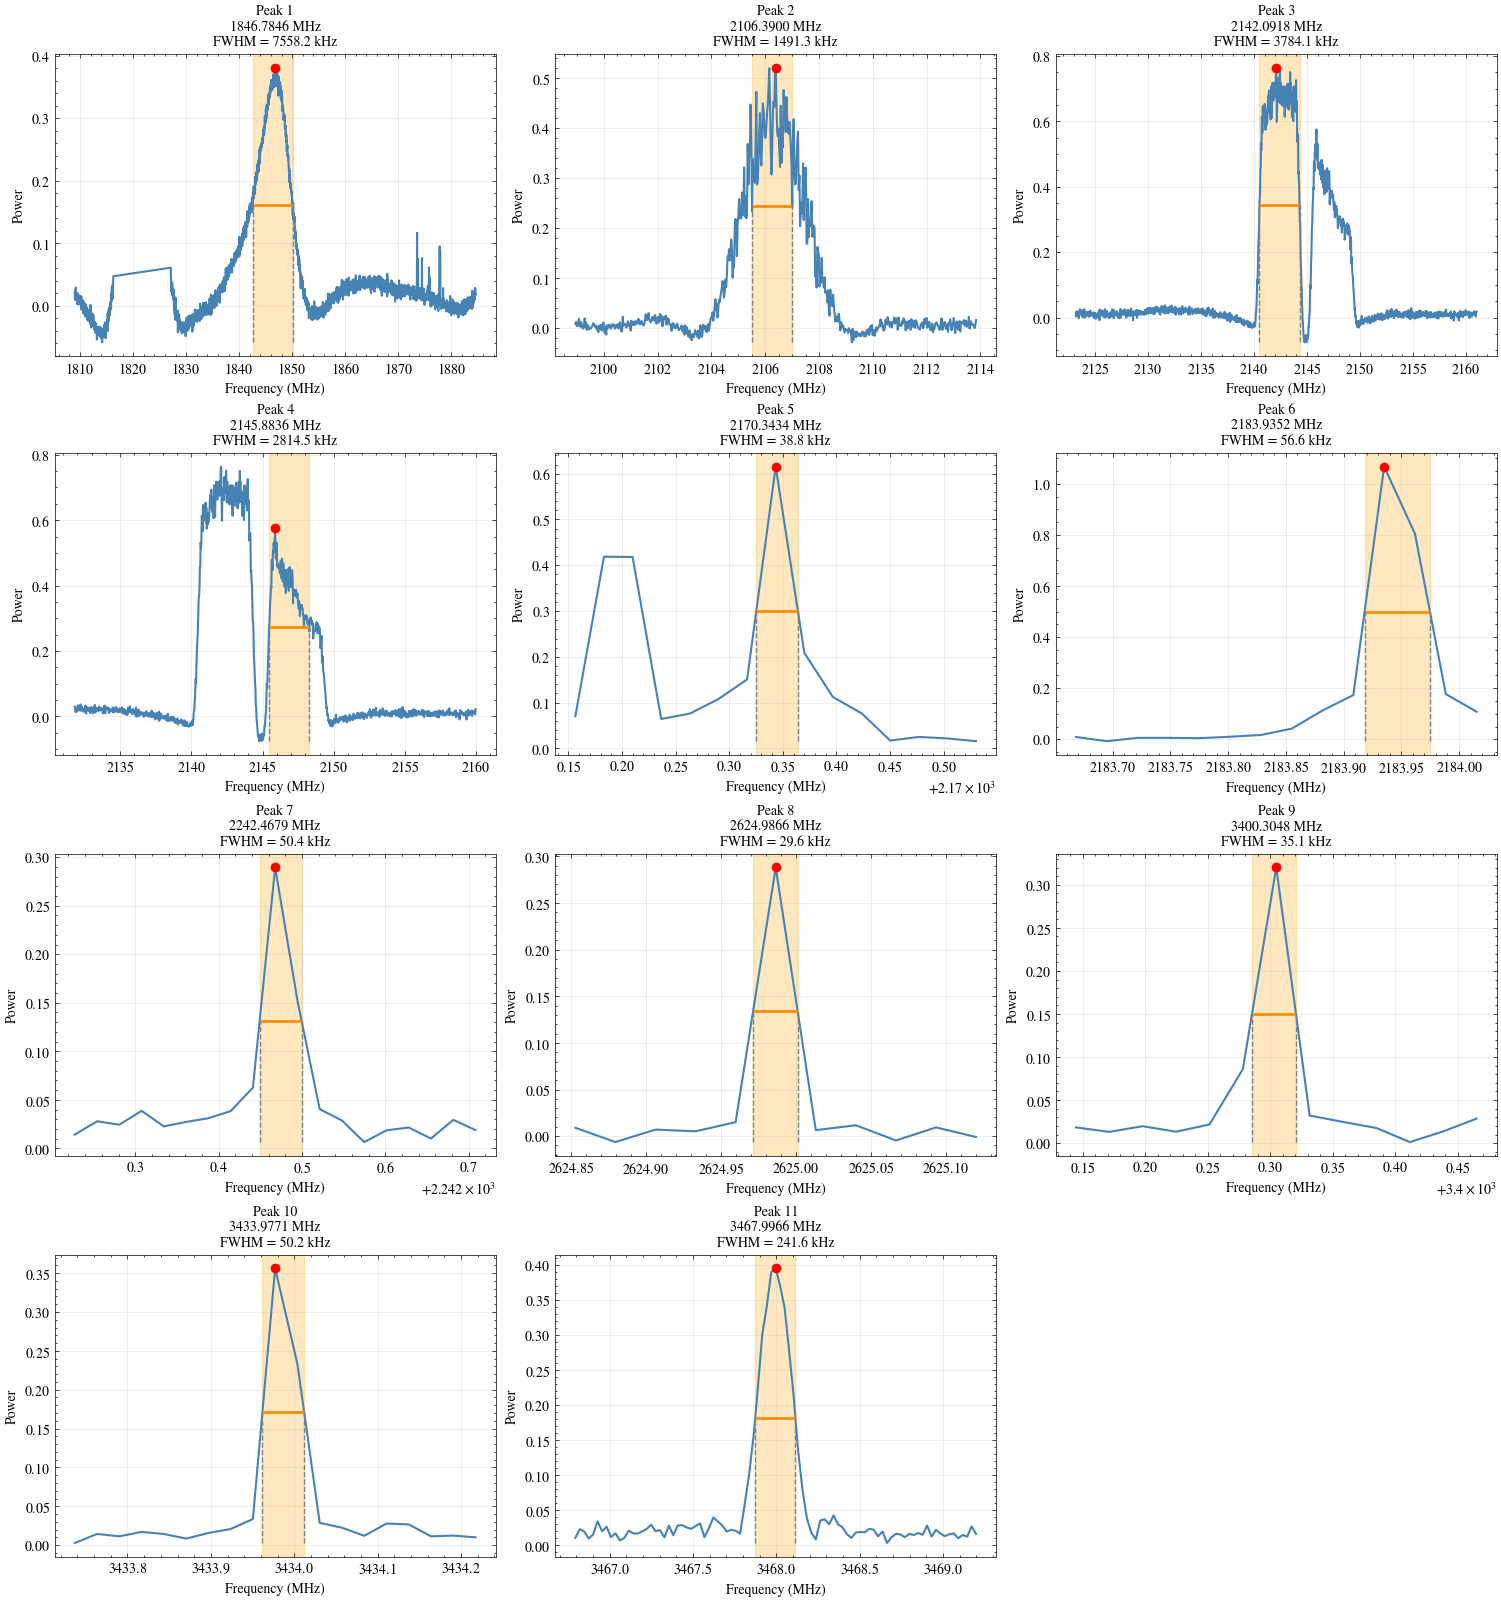

In [31]:


# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak

n_peaks = len(peaks_low)

ncols = 3
nrows = math.ceil(n_peaks / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5*ncols, 4*nrows),
    constrained_layout=True
)

axes = np.atleast_1d(axes).flatten()

for i, peak in enumerate(peaks_low):

    ax = axes[i]

    centre = mask_frequency[peak]

    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq_low[i]
    x_max = centre + window * fwhm_freq_low[i]

    mask = (mask_frequency >= x_min) & (mask_frequency <= x_max)

    # Spectrum
    ax.plot(
        mask_frequency[mask],
        mask_signal[mask],
        color="steelblue",
        lw=1.5
    )

    # Peak marker
    ax.plot(
        centre,
        mask_signal[peak],
        'ro',
        ms=6,
        label='Peak'
    )

    # FWHM line
    ax.hlines(
        width_heights_low[i],
        left_freq_low[i],
        right_freq_low[i],
        color='darkorange',
        lw=2,
        label='FWHM'
    )

    # Crossing points
    ax.vlines(
        [left_freq_low[i], right_freq_low[i]],
        ymin=mask_signal[mask].min(),
        ymax=width_heights_low[i],
        color='gray',
        linestyle='--'
    )

    # Shade the FWHM
    ax.axvspan(
        left_freq_low[i],
        right_freq_low[i],
        color='orange',
        alpha=0.25
    )

    ax.set_title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq_low[i]*1000:.1f} kHz",
        fontsize=10
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power")
    ax.grid(alpha=0.3)

# Remove empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.show()

/tmp/ipykernel_243540/2052592367.py:185: UserWarning: Glyph 7525 (\N{LATIN SUBSCRIPT SMALL LETTER V}) missing from font(s) STIXGeneral.
  fig.tight_layout()
/tmp/ipykernel_243540/2052592367.py:185: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 7525 (\N{LATIN SUBSCRIPT SMALL LETTER V}) missing from font(s) STIXGeneral.
  fig.canvas.print_figure(bytes_io, **kw)


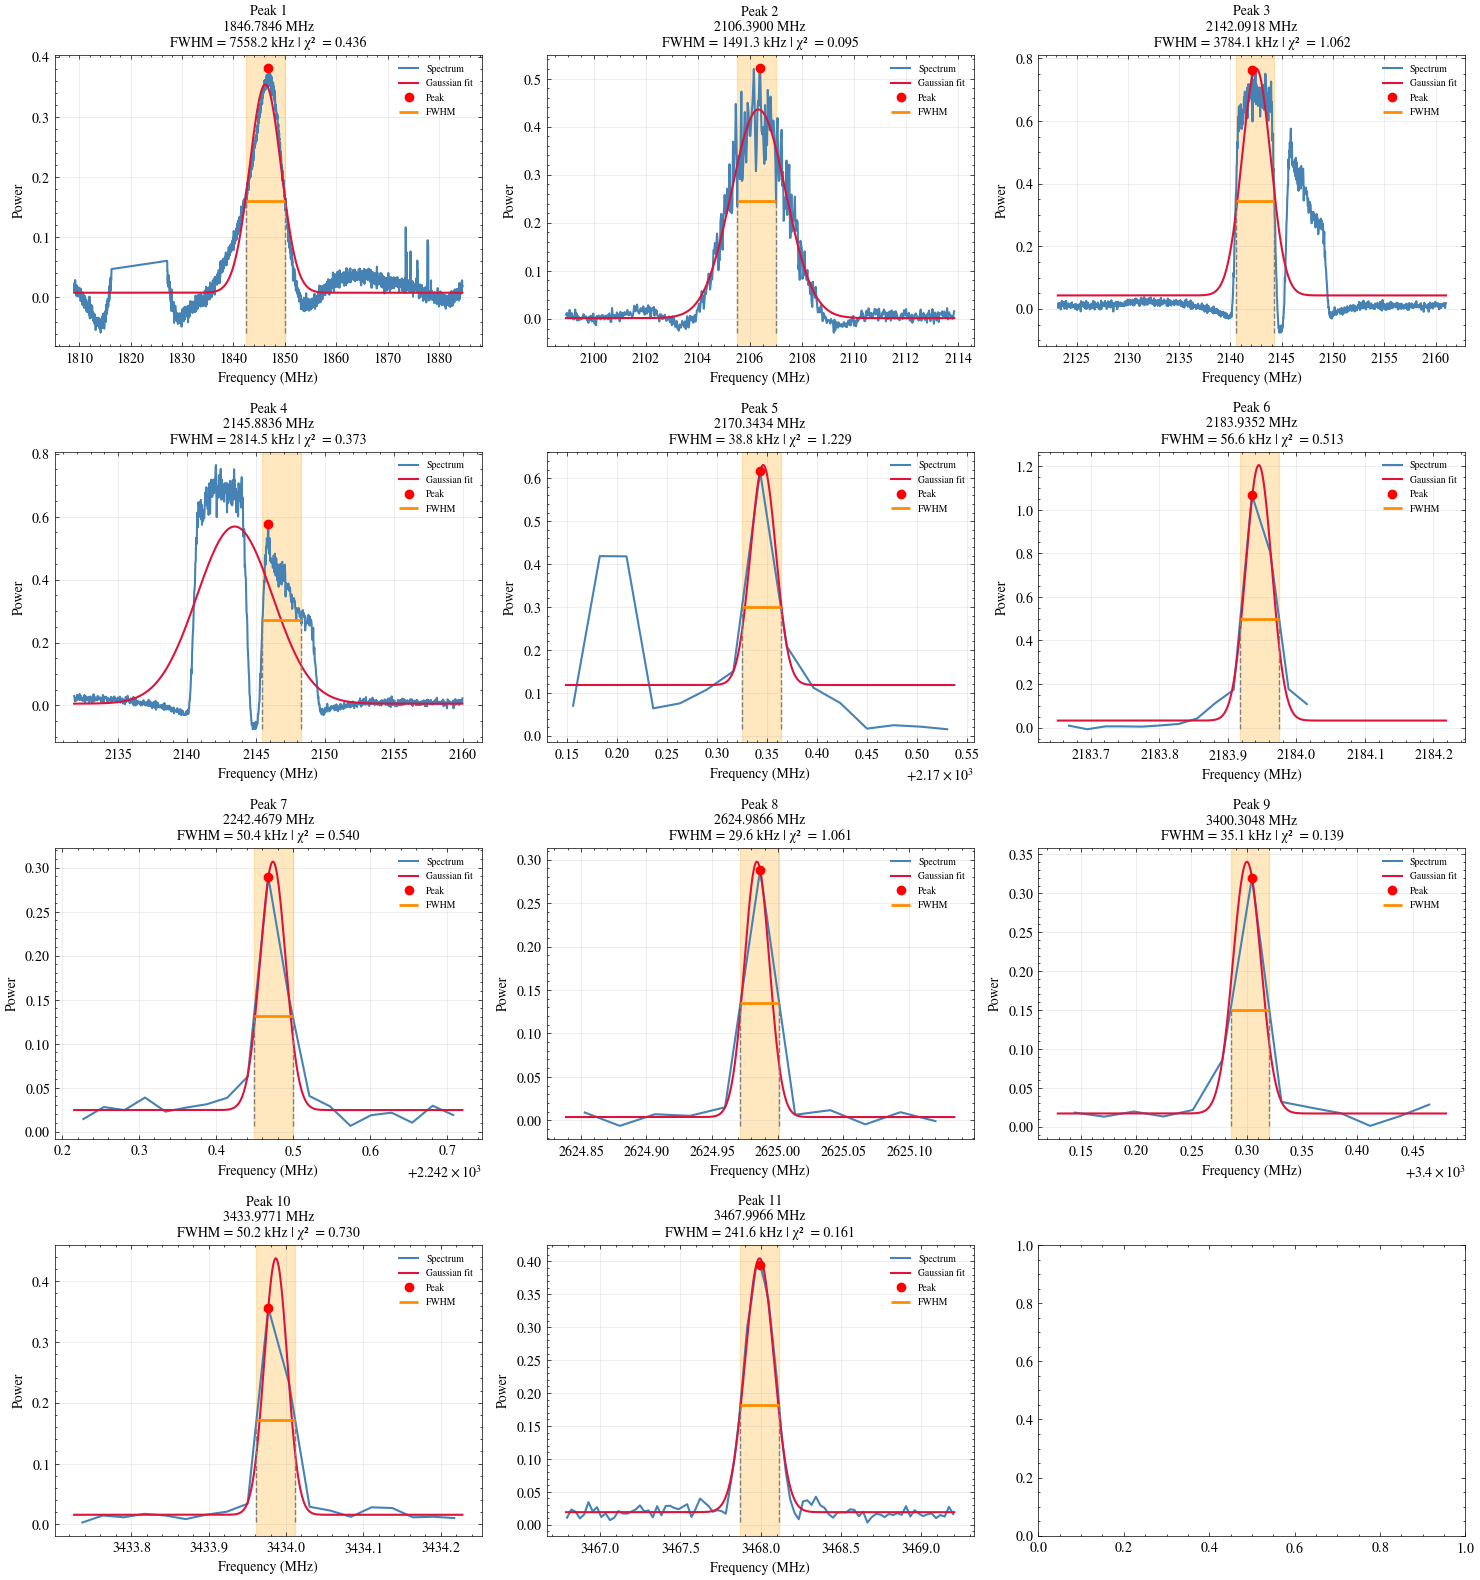

In [32]:


# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak

n_peaks = len(peaks_low)

ncols = 3
nrows = math.ceil(n_peaks / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5*ncols, 4*nrows),
    constrained_layout=True
)

axes = np.atleast_1d(axes).flatten()

gaussian_fit_results_low = []  # collect fit params + R^2 per peak

low_peak_details = []


for i, peak in enumerate(peaks_low):

    ax = axes[i]

    centre = mask_frequency[peak]

    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq_low[i]
    x_max = centre + window * fwhm_freq_low[i]

    mask = (mask_frequency >= x_min) & (mask_frequency <= x_max)

    x_data = mask_frequency[mask]
    y_data = mask_signal[mask]

    # Remove NaNs
    valid = np.isfinite(y_data)

    x_data = x_data[valid]
    y_data = y_data[valid]

    # Estimate noise from off-peak region
    off_peak_mask = (x_data < left_freq_low[i]) | (x_data > right_freq_low[i])

    if np.sum(off_peak_mask) > 5:
        noise_std = np.std(y_data[off_peak_mask])
    else:
        noise_std = np.std(y_data)

    noise_std = max(noise_std, 1e-6)

    sigma_array = np.full_like(y_data, noise_std)

    # -------------------------------------------------------
    # Gaussian fit
    # -------------------------------------------------------
    sigma_guess = fwhm_freq_low[i] / 2.35482

    amp_guess = np.max(y_data) - np.median(y_data)

    offset_guess = np.median(y_data)

    p0 = [
        amp_guess,
        centre,
        sigma_guess,
        offset_guess
    ]

    try:

        popt, pcov = curve_fit(
            gaussian,
            x_data,
            y_data,
            p0=p0,
            sigma=sigma_array,
            absolute_sigma=True,
            maxfev=10000
        )

        y_fit = gaussian(x_data, *popt)

        chi2, chi2_reduced = chi_squared(
            y_data,
            y_fit,
            sigma_array,
            n_params=4
        )

        x_smooth = np.linspace(x_min, x_max, 500)
        y_smooth = gaussian(x_smooth, *popt)

        fit_success = True

    except RuntimeError:

        fit_success = False
        popt = [np.nan]*4
        chi2 = np.nan
        chi2_reduced = np.nan


    gaussian_fit_results_low.append({
        "peak_freq_mhz": centre,
        "amplitude": popt[0],
        "fitted_centre_mhz": popt[1],
        "sigma_mhz": popt[2],
        "offset": popt[3],
        "noise_std": noise_std,
        "chi_squared": chi2,
        "reduced_chi_squared": chi2_reduced,
        "fit_success": fit_success,
    })


    # determine the OBW
    total_power = np.sum(y_data)
    cumulative_power = np.cumsum(y_data)
    lower_bound_idx = np.searchsorted(cumulative_power, 0.05 * total_power)
    upper_bound_idx = np.searchsorted(cumulative_power, 0.95 * total_power)
    obw_lower_freq = x_data[lower_bound_idx]
    obw_upper_freq = x_data[upper_bound_idx] 

    #occupaied bandwidth
    occupied_bandwidth = obw_upper_freq - obw_lower_freq

    # ratio obw to fwhm
    obw_to_fwhm_ratio = occupied_bandwidth / fwhm_freq_low[i]
      

    # create a data frame to store the results
    
    low_peak_details.append({
    
    "detected_frequency_[MHz]": centre,
    "fitted_frequency_[MHz]": popt[1],
    "fitted_amplitude_[dB]": popt[0],
    "detrended_signal_[dB]": spectrum_corrected[peak],
    "signal_amplitude_[dB]": mean_spectrum_db[peak],
    "occupied_bandwidth_[MHz]": occupied_bandwidth,
    "fwhm_[MHz]": fwhm_freq_low[i],
    "obw_to_fwhm_ratio": obw_to_fwhm_ratio
    })

    # -------------------------------------------------------
    # Spectrum
    # -------------------------------------------------------
    ax.plot(x_data, y_data, color="steelblue", lw=1.5, label="Spectrum")

    if fit_success:
        ax.plot(x_smooth, y_smooth, color="crimson", lw=1.5,
                 linestyle="-", label="Gaussian fit")

    ax.plot(centre, mask_signal[peak], 'ro', ms=6, label='Peak')

    ax.hlines(width_heights_low[i], left_freq_low[i], right_freq_low[i],
              color='darkorange', lw=2, label='FWHM')

    ax.vlines([left_freq_low[i], right_freq_low[i]],
              ymin=y_data.min(), ymax=width_heights_low[i],
              color='gray', linestyle='--')

    ax.axvspan(left_freq_low[i], right_freq_low[i], color='orange', alpha=0.25)

    chi2_str = f"{chi2_reduced:.3f}" if fit_success else "fit failed"
    ax.set_title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq_low[i]*1000:.1f} kHz | \u03c7\u00b2\u1d65 = {chi2_str}",
        fontsize=10
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Power")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")


# Remove empty axes
fig.tight_layout()

if to_save:
        # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_low_peak_gaussian_fits.png'),
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        os.path.join(full_path, f'{scan_name}_low_peak_gaussian_fits.pdf'),
        bbox_inches="tight",
        facecolor="white"
    )


plt.show()


In [33]:
# low_peak_details = []

# for i, peak in enumerate(peaks_low):
#     fit_result = gaussian_fit_results[i]

 
#     centre = mask_frequency[peak]
 
#     # Zoom window proportional to the measured FWHM
#     x_min = centre - window * fwhm_freq[i]
#     x_max = centre + window * fwhm_freq[i]
 
#     mask = (mask_frequency >= x_min) & (mask_frequency <= x_max)
 
#     x_data = mask_frequency[mask]
#     y_data = mask_signal[mask]

#     # determine the OBW
#     total_power = np.sum(y_data)
#     cumulative_power = np.cumsum(y_data)
#     lower_bound_idx = np.searchsorted(cumulative_power, 0.05 * total_power)
#     upper_bound_idx = np.searchsorted(cumulative_power, 0.95 * total_power)
#     obw_lower_freq = x_data[lower_bound_idx]
#     obw_upper_freq = x_data[upper_bound_idx]    

#     occupied_bandwidth = obw_upper_freq - obw_lower_freq

#     # ratio obw to fwhm
#     obw_to_fwhm_ratio = occupied_bandwidth / fwhm_freq[i]
    
#     print(f"Peak {i+1}:")
#     print(f"  Detected Frequency: {fit_result['peak_freq_mhz']:.4f} MHz")
#     print(f"  Gaussian Fitted Frequency: {fit_result['fitted_centre_mhz']:.4f} MHz")
#     print(f"  Fitted Amplitude: {fit_result['amplitude']:.4f}")
#     print(f"  Signal Amplitude: {spectrum_corrected[peak]:.4f}")
#     print(f"  Occupied Bandwidth: {occupied_bandwidth:.1f} MHz")
#     print(f"  FWHM              : {fwhm_freq[i]:.1f} MHz")
#     print(f"  OBW/FWHM Ratio    : {obw_to_fwhm_ratio:.4f}")

#     low_peak_details.append({
        
#         "detected_frequency": fit_result['peak_freq_mhz'],
#         "fitted_frequency": fit_result['fitted_centre_mhz'],
#         "fitted_amplitude": fit_result['amplitude'],
#         "signal_amplitude": spectrum_corrected[peak],
#         "occupied_bandwidth": occupied_bandwidth,
#         "fwhm": fwhm_freq[i],
#         "obw_to_fwhm_ratio": obw_to_fwhm_ratio
#     })

if to_save:
    # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)


    # convert the list into a DataFrame for better visualization
    low_peak_df = pd.DataFrame(low_peak_details)
    low_peak_df.to_csv(
        os.path.join(full_path, f"{dirname}_low_peak_details.csv"),
        index=False
    )


In [34]:
low_peak_df= pd.read_csv(os.path.join(full_path, f"{dirname}_low_peak_details.csv"))
low_peak_df

,detected_frequency_[MHz],fitted_frequency_[MHz],fitted_amplitude_[dB],detrended_signal_[dB],signal_amplitude_[dB],occupied_bandwidth_[MHz],fwhm_[MHz],obw_to_fwhm_ratio
0,1846.784592,1846.199821,0.346586,0.026518,243.986404,28.972626,7.558155,3.833293
1,2106.389999,2106.327774,0.433934,0.009040,246.885818,3.471375,1.491275,2.327789
2,2142.091751,2142.515844,0.724490,0.010423,247.771816,12.577057,3.784066,3.323689
3,2145.883560,2143.450189,0.563016,0.013950,247.885896,8.037567,2.814546,2.855725
4,2170.343399,2170.346499,0.512157,0.008384,248.574008,0.240326,0.038799,6.194058
5,2183.935165,2183.945165,1.172189,0.000412,248.987207,0.106812,0.056643,1.885707
6,2242.467880,2242.473902,0.282366,0.031306,249.059283,0.400543,0.050449,7.939505
7,2624.986649,2624.984213,0.294019,0.000886,248.841532,0.053406,0.029563,1.806515
8,3400.304794,3400.300249,0.323453,-0.008346,237.469313,0.267029,0.035088,7.610291
9,3433.977127,3433.986841,0.422387,0.015164,234.244457,0.320435,0.050181,6.385580
